<a href="https://colab.research.google.com/github/victorventu/PI-DataScience/blob/main/big-data/PI_BigData_v3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Projeto Integrador - Big Data**
## F.C.A. Serviços Pecuários e Comércio de Produtos Veterinários

- **Definição do problema:**

A F.C.A. Serviços Pecuários e Comércio de Produtos Veterinários atua no fornecimento de produtos e insumos destinados à pecuária, comercializando itens como suplementos, produtos de nutrição animal, medicamentos, materiais de consumo e outros produtos utilizados no manejo de rebanhos.

Um dos desafios enfrentados por empresas desse segmento está relacionado ao gerenciamento de estoque diante das variações da demanda ao longo do ano. Essas oscilações podem ocorrer em função de fatores como sazonalidade climática, calendário sanitário, períodos de manejo dos rebanhos e necessidades específicas dos produtores rurais.

Uma gestão inadequada pode ocasionar dois problemas principais: a falta de produtos em períodos de maior procura, provocando perdas de vendas e insatisfação dos clientes, e o excesso de mercadorias armazenadas, aumentando a imobilização de capital e o risco de sobras de estoque.

- **Pergunta para Análise:**

Como prever a demanda mensal por produto e identificar o comportamento de compra dos produtores rurais para otimizar a reposição de estoque, evitando rupturas em períodos de alta e sobras de estoque na F.C.A. Serviços Pecuários?

## **Descrição da Base:**

- **Origem:** Base de dados sintética (simulada) gerada por um programa em Python, com a mesma estrutura de 43 colunas do relatório de vendas da F.C.A. Os dados reais da empresa não podem ser usados porque têm informações comerciais e pessoais.

- **Período:** Janeiro de 2016 a Outubro de 2026.

- **Formato e Estrutura:** Arquivo CSV (separador ;), com uma linha para cada item de pedido.

- **Volume:** Aproximadamente 136.000 linhas (itens de pedido) de 100.000 pedidos simulados.

- **Limitações e Restrições:**
  - A base é simulada. A sazonalidade, o crescimento das vendas e o reajuste de preços (cerca de 6% ao ano) foram colocados no simulador, então os resultados precisam ser conferidos com a base real da empresa.
  - Algumas "sujeiras" foram colocadas de propósito (cerca de 15% das datas e dos textos com formato diferente) para praticar a limpeza.
  - A base só tem vendas. Não tem estoque, validade nem prazo de entrega do fornecedor. Por isso o projeto faz a **previsão da demanda**, que é o que ajuda a decidir a reposição, mas não calcula o estoque nem as perdas por vencimento.
  - Os campos de nota fiscal, cupom, cidade e estado só existem nos itens que geraram esses documentos.

## **Dicionário de Dados:**

| Coluna | Tipo | Descrição | Nulos esperados | Usada na análise? |
|---|---|---|---|---|
| `Nº Ped.` | inteiro | Número do pedido (se repete em cada item do pedido) | Não | Sim |
| `Nº Orc.` | inteiro | Número do orçamento que originou o pedido | Não | Não |
| `Dt.Ped.` | data/hora | Data e hora do pedido | Não | Sim |
| `Cliente` | texto | Nome do cliente (produtor rural ou pessoa) | Não | Sim |
| `Produto` | texto | Nome do produto ou serviço vendido | Não | Sim |
| `IdProduto` | inteiro | Código do produto | Não | Sim |
| `Qnt.` | inteiro | Quantidade vendida, na unidade da coluna `Un.` | Não | Sim |
| `Total Líquido` | decimal | Valor do item em R\$ (`Qnt.` × `Vr.Unit.`) | Não | Sim |
| `Vendedor` | texto | Vendedor responsável pelo pedido | Não | Sim |
| `Vr.Unit.` | decimal | Preço unitário de venda em R\$ | Não | Sim |
| `Grupo` | texto | Grupo do produto (7 grupos) | Não | Sim |
| `Marca` | texto | REPRESENTAÇÃO ou INDEFINIDA | Não | Não |
| `Fornecedor` | texto | Fornecedor do produto | Sim (serviços e parte dos itens) | Sim |
| `Tot.Kg Bruto` | decimal | Peso bruto total do item em kg (`Qnt.` × `Peso Br. Un.`) | Não | Não |
| `Total Bruto` | decimal | Valor antes do desconto (`Total Líquido` + `Tot.Desc.`) | Não | Não |
| `Peso Br. Un.` | decimal | Peso bruto por unidade vendida (kg) | Não | Não |
| `Dt.Cup.Sat.` | data/hora | Data/hora do cupom fiscal SAT | Sim (só vendas por cupom) | Não |
| `Dt.NF Lcto.` | data/hora | Data/hora do lançamento da nota fiscal | Sim (só vendas com NF) | Não |
| `N° NF.` | inteiro | Número da nota fiscal | Sim (só vendas com NF) | Só para criar o Tipo_Documento |
| `Dt.Cupom` | data/hora | Data/hora do cupom fiscal | Sim (só vendas por cupom) | Não |
| `Cód. NF.` | inteiro | Código da nota fiscal (igual a `N° NF.`) | Sim (só vendas com NF) | Não |
| `Dt.NF.Emis.` | data/hora | Data/hora de emissão da nota fiscal | Sim (só vendas com NF) | Não |
| `Nº Cup.` | inteiro | Número do cupom fiscal | Sim (só vendas por cupom) | Só para criar o Tipo_Documento |
| `Nº Cup.Sat.` | inteiro | Número do cupom SAT | Sim (só vendas por cupom) | Não |
| `Peso Líq. Un.` | decimal | Peso líquido por unidade vendida (kg) | Não | Não |
| `Tot.Desc.` | decimal | Desconto total do item em R\$ (0 quando não há desconto) | Não | Sim |
| `Cód.Cliente` | inteiro | Código do cliente | Não | Não |
| `Vr.Comiss.` | decimal | Comissão acumulada do vendedor no mês, em R\$ | Não | Não |
| `Un.` | texto | Unidade de venda (KG, SC, UN, PC, LT, MIL) | Não | Sim |
| `Condição` | texto | Condição de pagamento | Não | Sim |
| `Tot.Kg Líq.` | decimal | Peso líquido total do item em kg | Não | Não |
| `SubGrupo` | texto | Subcategoria dentro do grupo | Sim (≈15% em branco) | Não |
| `Venc. Pedido` | data | Data de vencimento do pedido | Não | Não |
| `Emissão Fin.` | data | Data de emissão financeira | Não | Não |
| `Vr.Total NF.` | decimal | Valor do item na nota fiscal (0 quando não faturado) | Não | Não |
| `Venc. Cupom` | data | Data de vencimento do cupom | Sim (quase sempre) | Não |
| `Venc. Nota` | data | Data de vencimento da nota fiscal | Sim (só vendas com NF) | Não |
| `Título` | texto | Identificador do título financeiro do item | Não | Não |
| `Cidade` | texto | Cidade registrada na nota fiscal | Sim (só vendas com NF) | Sim |
| `Estado` | texto | UF registrada na nota fiscal | Sim (só vendas com NF) | Sim |
| `Tipo Venda` | texto | PRODUTOS, REPRESENTAÇÃO ou SERVIÇOS | Não | Sim |
| `Preço Compra.` | decimal | Custo de compra unitário em R\$ | Sim (serviços não têm custo) | Sim |
| `Modelo NF` | inteiro | Modelo da nota fiscal (55 = NF-e) | Sim (só vendas com NF) | Não |

> Das 43 colunas, usamos 18 e criamos algumas novas. O motivo de cada coluna removida está na parte de **Seleção de Colunas** da EDA.

## **5 Vs do Big Data:**

- **Volume:** Uma década de histórico de vendas (cerca de 136 mil linhas). É um volume pequeno para um projeto real, mas o histórico de uma empresa só cresce, então a arquitetura (Data Warehouse e Spark) foi pensada para volumes maiores.

- **Velocidade:** Novos pedidos, cupons e notas fiscais são gerados o tempo todo no sistema de vendas. O simulador tem um modo contínuo (streaming) que imita esse fluxo.

- **Variedade:** Os dados são de vários tipos de documento (pedido, nota fiscal, cupom e financeiro), com datas em formatos diferentes e textos escritos de formas diferentes.

- **Veracidade:** Os dados têm datas em formatos misturados, nomes em maiúsculo e minúsculo e códigos de cliente repetidos. Se não tratarmos isso, as contagens e os gráficos ficam errados.

- **Valor:** Com a previsão de demanda e o perfil dos clientes, a empresa evita comprar demais (capital parado) e evita faltar produto (venda perdida).

# Análise Exploratória de Dados (EDA)

In [ ]:
# Bibliotecas de manipulação e visualização
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter
from sklearn.preprocessing import StandardScaler

sns.set_theme(style='whitegrid')

# Funções para escrever os números dos eixos de forma simples (ex: R$ 1.000 em vez de 10^3)
def formato_milhar(valor, posicao=None):
    return f'{valor:,.0f}'.replace(',', '.')

def eixo_em_reais(eixo):
    eixo.set_major_formatter(FuncFormatter(lambda valor, posicao: 'R$ ' + formato_milhar(valor)))
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)

In [ ]:
# Conexão com o Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Carregamento do dataset gerado (com separador ponto e vírgula)
caminho_csv = '/content/drive/MyDrive/PI_DataScience/Gerador/vendas.csv'
df = pd.read_csv(caminho_csv, sep=';', low_memory=False)

# Visualização das 5 primeiras linhas
display(df.head())

,Nº Ped.,Nº Orc.,Dt.Ped.,Cliente,Produto,IdProduto,Qnt.,Total Líquido,Vendedor,Vr.Unit.,Grupo,Marca,Fornecedor,Tot.Kg Bruto,Total Bruto,Peso Br. Un.,Dt.Cup.Sat.,Dt.NF Lcto.,N° NF.,Dt.Cupom,Cód. NF.,Dt.NF.Emis.,Nº Cup.,Nº Cup.Sat.,Peso Líq. Un.,Tot.Desc.,Cód.Cliente,Vr.Comiss.,Un.,Condição,Tot.Kg Líq.,SubGrupo,Venc. Pedido,Emissão Fin.,Vr.Total NF.,Venc. Cupom,Venc. Nota,Título,Cidade,Estado,Tipo Venda,Preço Compra.,Modelo NF
0,14600,12701,2016-01-01 07:56:03,agropecuária carvalho,REAGENTE ANALISE DE LEITE 1L,1091,10,358.60,BRENDA ALVES,35.86,QUALIDADE DE LEITE,INDEFINIDA,MONTENEGRO PEREIRA S/A EIRELI,10.770,358.60,1.077,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.055,0.0,1341,10.76,LT,81-100/200 DIAS,10.550,Higienização,2016-02-15,01/01/16,0.00,NaN,NaN,0014600-1/1,NaN,NaN,PRODUTOS,30.01,NaN
1,14601,12702,01-01-2016 08:04:11,júlia porto,REAGENTE ANALISE DE LEITE 1L,1091,10,337.60,BRENDA ALVES,33.76,QUALIDADE DE LEITE,INDEFINIDA,BORGES S.A. LTDA,10.060,337.60,1.006,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.986,0.0,4829,20.89,LT,2-30 DIAS,9.860,Higienização,16/01/16,01/01/16,0.00,NaN,NaN,0014601-1/1,NaN,NaN,PRODUTOS,28.69,NaN
2,14602,12703,2016-01-01 08:17:42,DR. JOÃO APARECIDA,DESINFETANTE INDUSTRIAL 5L,1104,8,184.56,BRENDA ALVES,23.07,QUIMICOS,INDEFINIDA,ANDRADE LTDA,3.416,184.56,0.427,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.422,0.0,1228,26.42,PC,66-7 DIAS,3.376,Desinfetante,01/03/16,01/01/16,0.00,NaN,NaN,0014602-1/1,NaN,NaN,PRODUTOS,16.21,NaN
3,14603,12704,2016-01-01 08:57:50,SR. YURI DA CONCEIÇÃO,DETERGENTE ACIDO CIP 20L,1117,5,233.05,SRA. ISABELLY CÂMARA,46.61,QUIMICOS,INDEFINIDA,Borges S.A. Ltda,8.510,233.05,1.702,NaN,2016-01-01 09:03:50,6997.0,NaN,6997.0,2016-01-01 09:26:50,NaN,NaN,1.666,0.0,2474,6.99,PC,63-28 DIAS,8.330,Desinfetante,16/01/2016,01/01/16,233.05,NaN,16/01/16,006997-1/1,BRITO DO OESTE,MA,PRODUTOS,31.95,55.0
4,14604,12705,2016-01-01 08:58:00,CHÁCARA MARQUES,SAL MINERAL EQUILIBRIO 25KG,1052,3000,9360.00,CAUÃ ROCHA,3.12,NUTRIÇÃO,INDEFINIDA,MONTENEGRO PEREIRA S/A EIRELI,3000.000,9547.20,1.000,NaN,2016-01-01 08:59:00,6998.0,NaN,6998.0,2016-01-01 09:29:00,NaN,NaN,0.986,187.2,443,280.80,KG,66-7 DIAS,2958.000,Concentrado Proteico,01/03/16,01/01/16,9360.00,NaN,01/03/16,006998-1/2,cassiano,BA,PRODUTOS,2.22,55.0


## Visão Geral da Base

In [ ]:
# Resumo dos tipos de dados e memória
print("--- Informações do Dataset ---")
print(df.info())

# Estatística descritiva (Contagem, Média, Desvio Padrão, Quartis)
print("\n--- Estatística Descritiva ---")
display(df.describe())

--- Informações do Dataset ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 136052 entries, 0 to 136051
Data columns (total 43 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   Nº Ped.        136052 non-null  int64  
 1   Nº Orc.        136052 non-null  int64  
 2   Dt.Ped.        136052 non-null  object 
 3   Cliente        136052 non-null  object 
 4   Produto        136052 non-null  object 
 5   IdProduto      136052 non-null  int64  
 6   Qnt.           136052 non-null  int64  
 7   Total Líquido  136052 non-null  float64
 8   Vendedor       136052 non-null  object 
 9   Vr.Unit.       136052 non-null  float64
 10  Grupo          136052 non-null  object 
 11  Marca          136052 non-null  object 
 12  Fornecedor     99540 non-null   object 
 13  Tot.Kg Bruto   136052 non-null  float64
 14  Total Bruto    136052 non-null  float64
 15  Peso Br. Un.   136052 non-null  float64
 16  Dt.Cup.Sat.    31138 non-null   object 
 17

,Nº Ped.,Nº Orc.,IdProduto,Qnt.,Total Líquido,Vr.Unit.,Tot.Kg Bruto,Total Bruto,Peso Br. Un.,N° NF.,Cód. NF.,Nº Cup.,Nº Cup.Sat.,Peso Líq. Un.,Tot.Desc.,Cód.Cliente,Vr.Comiss.,Tot.Kg Líq.,Vr.Total NF.,Preço Compra.,Modelo NF
count,136052.000000,136052.000000,136052.000000,136052.000000,136052.000000,136052.000000,136052.000000,136052.000000,136052.000000,63998.000000,63998.000000,31138.000000,31138.000000,136052.000000,136052.000000,136052.000000,136052.000000,136052.000000,136052.000000,119518.000000,63998.0
mean,64576.475634,62677.475634,1096.202026,248.252029,1533.477519,40.083839,248.153782,1554.561886,0.954761,30517.092269,30517.092269,20236.460434,20237.971129,0.933208,21.084368,2378.829198,6586.417545,243.147822,729.778284,19.202473,55.0
std,28878.102937,28878.102937,60.596193,667.491536,3836.123879,47.236376,667.562884,3889.725322,0.459891,13594.061242,13594.061242,6608.642050,6608.645201,0.448917,95.947902,1361.044417,4963.684063,654.242297,2791.924994,20.253537,0.0
min,14600.000000,12701.000000,1000.000000,1.000000,9.650000,1.180000,0.001000,9.840000,0.001000,6997.000000,6997.000000,8800.000000,8800.000000,0.001000,0.000000,100.000000,0.400000,0.001000,0.000000,0.670000,55.0
25%,39593.750000,37694.750000,1039.000000,5.000000,128.080000,4.070000,3.122000,130.050000,0.814000,18759.250000,18759.250000,14505.250000,14506.750000,0.794000,0.000000,1217.000000,2700.000000,3.050000,0.000000,2.600000,55.0
50%,64554.500000,62655.500000,1091.000000,25.000000,402.465000,24.020000,22.450000,408.430000,1.000000,30485.500000,30485.500000,20243.500000,20244.000000,0.980000,0.000000,2406.000000,5572.800000,21.870000,0.000000,12.540000,55.0
75%,89580.250000,87681.250000,1143.000000,50.000000,1142.000000,58.590000,57.480000,1155.682500,1.069000,42294.000000,42294.000000,25945.750000,25945.750000,1.046000,7.210000,3454.000000,9399.815000,56.130000,356.170000,28.480000,55.0
max,114599.000000,112700.000000,1195.000000,3000.000000,50280.000000,298.600000,3000.000000,51285.600000,2.000000,54080.000000,54080.000000,31664.000000,31666.000000,1.998000,2436.000000,4985.000000,29271.510000,3000.000000,50280.000000,115.080000,55.0


In [ ]:
# Tratamento e Identificação de Nulos / Duplicados

# Contagem de valores nulos por coluna
print("--- Valores Nulos ---")
print(df.isnull().sum())

# Contagem de linhas completamente duplicadas
print(f"\nLinhas duplicadas na base: {df.duplicated().sum()}")

--- Valores Nulos ---
Nº Ped.               0
Nº Orc.               0
Dt.Ped.               0
Cliente               0
Produto               0
IdProduto             0
Qnt.                  0
Total Líquido         0
Vendedor              0
Vr.Unit.              0
Grupo                 0
Marca                 0
Fornecedor        36512
Tot.Kg Bruto          0
Total Bruto           0
Peso Br. Un.          0
Dt.Cup.Sat.      104914
Dt.NF Lcto.       72054
N° NF.            72054
Dt.Cupom         104914
Cód. NF.          72054
Dt.NF.Emis.       72054
Nº Cup.          104914
Nº Cup.Sat.      104914
Peso Líq. Un.         0
Tot.Desc.             0
Cód.Cliente           0
Vr.Comiss.            0
Un.                   0
Condição              0
Tot.Kg Líq.           0
SubGrupo          20354
Venc. Pedido          0
Emissão Fin.          0
Vr.Total NF.          0
Venc. Cupom      133419
Venc. Nota        72054
Título                0
Cidade            72054
Estado            72054
Tipo Venda        

In [ ]:
# Contagem de Variáveis Categóricas Chave

# Perfil de vendas por Grupo de Produto
print("--- Vendas por Grupo ---")
print(df['Grupo'].value_counts())

# Unidades de medida mais comuns
print("\n--- Unidades de Medida ---")
print(df['Un.'].value_counts())

--- Vendas por Grupo ---
Grupo
NUTRIÇÃO              44655
SERVIÇO               16534
QUIMICOS              16503
QUALIDADE DE LEITE    16461
USO E CONSUMO         16441
GERAL                 16414
KM                     9044
Name: count, dtype: int64

--- Unidades de Medida ---
Un.
UN     41209
KG     35799
PC     24679
SC     17900
MIL     8265
LT      8200
Name: count, dtype: int64


**Interpretação:**

- A base tem 136.052 linhas e 43 colunas (100 mil pedidos, com 1 a 3 itens cada) e não tem linhas duplicadas.
- Quase todos os valores ausentes são esperados. Os campos de nota fiscal só existem nos itens que tiveram NF (cerca de 53% de nulos), os de cupom só nos itens vendidos com cupom (cerca de 77% de nulos) e o `Preço Compra.` é nulo nos serviços.
- `NUTRIÇÃO` é o grupo com mais linhas (cerca de 33%).
- As datas estão como texto (`object`) e alguns textos estão escritos de formas diferentes. Vamos ver isso agora.

## Diagnóstico da Base

Antes de limpar, vamos medir os problemas da base.

In [ ]:
# Formatos de data misturados
def formato_data(valor):
    if pd.isna(valor):
        return 'Nulo'
    padroes = {
        r'\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2}': 'AAAA-MM-DD hh:mm:ss',
        r'\d{2}/\d{2}/\d{4} \d{2}:\d{2}:\d{2}': 'DD/MM/AAAA hh:mm:ss',
        r'\d{2}-\d{2}-\d{4} \d{2}:\d{2}:\d{2}': 'DD-MM-AAAA hh:mm:ss',
        r'\d{4}/\d{2}/\d{2} \d{2}:\d{2}:\d{2}': 'AAAA/MM/DD hh:mm:ss',
        r'\d{2}/\d{2}/\d{2}': 'DD/MM/AA',
        r'\d{2}-\d{2}-\d{2}': 'DD-MM-AA',
        r'\d{2}/\d{2}/\d{4}': 'DD/MM/AAAA',
        r'\d{4}-\d{2}-\d{2}': 'AAAA-MM-DD',
    }
    for padrao, nome in padroes.items():
        if re.fullmatch(padrao, valor):
            return nome
    return 'Outro'

print('Formatos da coluna Dt.Ped.:')
print(df['Dt.Ped.'].map(formato_data).value_counts())

Formatos da coluna Dt.Ped.:
Dt.Ped.
AAAA-MM-DD hh:mm:ss    115451
DD-MM-AAAA hh:mm:ss      6937
DD/MM/AAAA hh:mm:ss      6918
AAAA/MM/DD hh:mm:ss      6746
Name: count, dtype: int64


In [ ]:
# Textos escritos de formas diferentes (maiúsculo, minúsculo...)
for col in ['Cliente', 'Vendedor', 'Fornecedor', 'Cidade']:
    antes = df[col].nunique()
    depois = df[col].str.strip().str.upper().nunique()
    print(f'{col}: {antes} valores diferentes -> {depois} depois de padronizar')

# O Cód.Cliente identifica um cliente só?
cliente_padronizado = df['Cliente'].str.strip().str.upper()
print('\nClientes diferentes (nome padronizado):', cliente_padronizado.nunique())
print('Códigos de cliente diferentes:', df['Cód.Cliente'].nunique())

Cliente: 1078 valores diferentes -> 366 depois de padronizar
Vendedor: 12 valores diferentes -> 4 depois de padronizar
Fornecedor: 15 valores diferentes -> 5 depois de padronizar
Cidade: 75 valores diferentes -> 25 depois de padronizar

Clientes diferentes (nome padronizado): 366
Códigos de cliente diferentes: 354


In [ ]:
# Conferindo algumas regras da base
total_calculado = df['Qnt.'] * df['Vr.Unit.']
print('Total Líquido diferente de Qnt. x Vr.Unit.:', (~np.isclose(df['Total Líquido'], total_calculado, atol=0.011)).sum())
print('Quantidades menores ou iguais a zero:', (df['Qnt.'] <= 0).sum())
print('Preços menores ou iguais a zero:', (df['Vr.Unit.'] <= 0).sum())
print('Itens com NF e cupom ao mesmo tempo:', (df['N° NF.'].notna() & df['Nº Cup.'].notna()).sum())

Total Líquido diferente de Qnt. x Vr.Unit.: 0
Quantidades menores ou iguais a zero: 0
Preços menores ou iguais a zero: 0
Itens com NF e cupom ao mesmo tempo: 0


**Interpretação:**

- **Datas:** cerca de 85% estão no formato padrão e cerca de 15% estão em outros formatos (como `DD/MM/AAAA`).
- **Textos:** a mesma pessoa ou cidade aparece escrita de formas diferentes, então a contagem fica errada (4 vendedores viram 12 e 25 cidades viram 75).
- **Código do cliente:** são 366 clientes mas só 354 códigos, ou seja, o mesmo código é usado por clientes diferentes. Por isso vamos usar o **nome do cliente** (padronizado) e não o `Cód.Cliente`.
- **Regras:** o total do item é sempre `Qnt.` x `Vr.Unit.` e não existem quantidades ou preços inválidos.

*(Esses números são da base gerada com `--seed 42`.)*

## Vendas Grandes (os "outliers")

A empresa tem vendas muito grandes e vendas pequenas. Essas vendas grandes **não são erros**: um produtor pode comprar muita sacaria de uma vez. Elas são reais, só que são menos comuns. Então não vamos apagar esses valores.

Primeiro vamos medir o tamanho do problema.

In [ ]:
# Tamanho das vendas (Total Líquido por linha)
total = df['Total Líquido'].sort_values(ascending=False)
n = len(total)

print(f"Mediana (venda típica): R$ {total.median():,.2f}")
print(f"Média: R$ {total.mean():,.2f}")
print(f"90% das vendas são menores que: R$ {total.quantile(0.90):,.2f}")
print(f"Maior venda: R$ {total.max():,.2f} (é {total.max() / total.median():.0f} vezes a mediana)")
print(f"\nAs 10% maiores vendas somam {total.iloc[:int(n * 0.10)].sum() / total.sum() * 100:.1f}% da receita total")
print(f"As 1% maiores vendas somam {total.iloc[:int(n * 0.01)].sum() / total.sum() * 100:.1f}% da receita total")

# Por grupo: mediana x maior venda
df.groupby('Grupo')['Total Líquido'].agg(Mediana='median', Maior_Venda='max').round(0).sort_values('Maior_Venda', ascending=False)

Mediana (venda típica): R$ 402.47
Média: R$ 1,533.48
90% das vendas são menores que: R$ 3,500.36
Maior venda: R$ 50,280.00 (é 125 vezes a mediana)

As 10% maiores vendas somam 64.0% da receita total
As 1% maiores vendas somam 20.0% da receita total


,Mediana,Maior_Venda
Grupo,,
NUTRIÇÃO,562.0,50280.0
KM,448.0,14130.0
SERVIÇO,1016.0,8734.0
QUIMICOS,428.0,3545.0
GERAL,265.0,1916.0
QUALIDADE DE LEITE,253.0,1783.0
USO E CONSUMO,201.0,1391.0


**Interpretação:** a maior venda é mais de 100 vezes maior que a venda típica, e as 10% maiores vendas representam quase dois terços da receita. Ou seja, **tirar essas vendas seria tirar justamente o que mais importa para a empresa**.

**O que vamos fazer com esses valores:**

1. **Manter** todos os valores na base.
2. Nos gráficos, usar a **escala logarítmica** (cada marca do eixo vale 10 vezes a anterior). Assim dá para ver as vendas pequenas e as grandes no mesmo gráfico.
3. Nos modelos (K-Means e Random Forest), usar o **StandardScaler** para colocar as variáveis na mesma escala.
4. Chamar de **vendas grandes**, e não de outliers, porque são valores reais.

## Limpeza

| Problema | O que fizemos |
|---|---|
| Datas em formatos diferentes | Converter tudo para data, testando cada formato (sem `dayfirst`, porque ele pode trocar dia e mês) |
| Nomes em maiúsculo e minúsculo | Tirar espaços sobrando e deixar tudo em MAIÚSCULO |
| `Cód.Cliente` repetido para clientes diferentes | Usar o nome do cliente padronizado |
| Nulos de NF e cupom | Manter os nulos e criar a coluna `Tipo_Documento` (Nota Fiscal, Cupom Fiscal ou Sem documento) |
| `Fornecedor` em branco | Preencher com `NÃO INFORMADO` |
| `Preço Compra.` nulo nos serviços | Manter nulo (serviço não tem custo de compra) |
| Vendas grandes | Manter (são reais) |

In [ ]:
# Guarda uma cópia da base original para comparar depois
df_bruto = df.copy()

In [ ]:
# 1) Padronização das datas
FORMATOS_DATA_HORA = ['%Y-%m-%d %H:%M:%S', '%d/%m/%Y %H:%M:%S', '%d-%m-%Y %H:%M:%S', '%Y/%m/%d %H:%M:%S']
FORMATOS_DATA_CURTA = ['%d/%m/%y', '%d-%m-%y', '%d/%m/%Y', '%Y-%m-%d']

def padronizar_data(serie, formatos):
    # Testa cada formato nos valores que ainda não foram convertidos
    resultado = pd.Series(pd.NaT, index=serie.index, dtype='datetime64[ns]')
    for formato in formatos:
        pendentes = resultado.isna() & serie.notna()
        if not pendentes.any():
            break
        resultado.loc[pendentes] = pd.to_datetime(serie[pendentes], format=formato, errors='coerce')
    return resultado

colunas_data_hora = ['Dt.Ped.', 'Dt.Cup.Sat.', 'Dt.NF Lcto.', 'Dt.Cupom', 'Dt.NF.Emis.']
colunas_data_curta = ['Venc. Pedido', 'Emissão Fin.', 'Venc. Cupom', 'Venc. Nota']

for col in colunas_data_hora:
    df[col] = padronizar_data(df_bruto[col], FORMATOS_DATA_HORA)
for col in colunas_data_curta:
    df[col] = padronizar_data(df_bruto[col], FORMATOS_DATA_CURTA)

# Confere se nenhuma data foi perdida na conversão
for col in colunas_data_hora + colunas_data_curta:
    assert df_bruto[col].notna().sum() == df[col].notna().sum(), f'Perdemos datas na coluna {col}'

print('Datas convertidas sem perder nenhum valor.')
print('Período dos pedidos:', df['Dt.Ped.'].min(), 'até', df['Dt.Ped.'].max())

Datas convertidas sem perder nenhum valor.
Período dos pedidos: 2016-01-01 07:56:03 até 2026-10-31 11:56:19


In [ ]:
# 2) Padronização dos textos (tudo em maiúsculo)
for col in ['Cliente', 'Vendedor', 'Fornecedor', 'Cidade']:
    df[col] = df[col].str.strip().str.upper()

print('Vendedores:', df['Vendedor'].nunique(), '| Clientes:', df['Cliente'].nunique(), '| Cidades:', df['Cidade'].nunique())

Vendedores: 4 | Clientes: 366 | Cidades: 25


In [ ]:
# 3) Tipo de documento (a partir dos campos de NF e cupom) e nulos
df['Tipo_Documento'] = np.select(
    [df['N° NF.'].notna(), df['Nº Cup.'].notna()],
    ['Nota Fiscal', 'Cupom Fiscal'],
    default='Sem documento'
)

df['Fornecedor'] = df['Fornecedor'].fillna('NÃO INFORMADO')

df['Tipo_Documento'].value_counts()

,count
Tipo_Documento,
Nota Fiscal,63998
Sem documento,40916
Cupom Fiscal,31138


## Seleção de Colunas

A base tem 43 colunas, mas várias não mudam em nada a análise. Para deixar a base mais enxuta, vamos conferir **por código** quais colunas são repetidas, constantes ou calculadas a partir de outras, e depois removê-las.

In [ ]:
# Conferindo, por código, o motivo de cada coluna que vamos remover
com_nf = df['N° NF.'].notna()

evidencias = pd.DataFrame([
    ('Modelo NF',        'Tem um valor só (55)',                                     df['Modelo NF'].nunique() == 1),
    ('Cód. NF.',         'É igual ao N° NF.',                                        df['Cód. NF.'].equals(df['N° NF.'])),
    ('Nº Orc.',          'É o Nº Ped. menos um número fixo',                         (df['Nº Ped.'] - df['Nº Orc.']).nunique() == 1),
    ('Total Bruto',      'É o Total Líquido + Tot.Desc.',                            np.allclose(df['Total Bruto'], df['Total Líquido'] + df['Tot.Desc.'], atol=0.02)),
    ('Tot.Kg Bruto',     'É Qnt. x Peso Br. Un.',                                    np.allclose(df['Tot.Kg Bruto'], df['Qnt.'] * df['Peso Br. Un.'], atol=0.01)),
    ('Tot.Kg Líq.',      'É Qnt. x Peso Líq. Un.',                                   np.allclose(df['Tot.Kg Líq.'], df['Qnt.'] * df['Peso Líq. Un.'], atol=0.01)),
    ('Emissão Fin.',     'É o mesmo dia do pedido',                                  (df['Emissão Fin.'] == df['Dt.Ped.'].dt.normalize()).all()),
    ('Venc. Nota',       'É igual ao Venc. Pedido (itens com NF)',                   (df.loc[com_nf, 'Venc. Nota'] == df.loc[com_nf, 'Venc. Pedido']).all()),
    ('Vr.Total NF.',     'É o Total Líquido (com NF) ou zero (sem NF)',              np.allclose(df.loc[com_nf, 'Vr.Total NF.'], df.loc[com_nf, 'Total Líquido']) and (df.loc[~com_nf, 'Vr.Total NF.'] == 0).all()),
    ('Marca',            'Já aparece no Tipo Venda (REPRESENTAÇÃO ou não)',          (df['Marca'] == 'REPRESENTAÇÃO').equals(df['Tipo Venda'] == 'REPRESENTAÇÃO')),
    ('SubGrupo',         'O mesmo produto tem vários SubGrupos diferentes',          df.groupby('Produto')['SubGrupo'].nunique().max() > 1),
    ('Cód.Cliente',      'Repete para clientes diferentes (usamos o nome)',          df['Cód.Cliente'].nunique() < df['Cliente'].nunique()),
    ('Título',           'É um identificador, diferente em todas as linhas',         df['Título'].is_unique),
    ('Vr.Comiss.',       'É a comissão acumulada do mês, somar não faz sentido',     df.groupby('Vendedor')['Vr.Comiss.'].nunique().min() > 100),
], columns=['Coluna', 'Motivo', 'Confirmado?'])

display(evidencias)
assert evidencias['Confirmado?'].all(), 'Alguma conferência falhou'

,Coluna,Motivo,Confirmado?
0,Modelo NF,Tem um valor só (55),True
1,Cód. NF.,É igual ao N° NF.,True
2,Nº Orc.,É o Nº Ped. menos um número fixo,True
3,Total Bruto,É o Total Líquido + Tot.Desc.,True
4,Tot.Kg Bruto,É Qnt. x Peso Br. Un.,True
5,Tot.Kg Líq.,É Qnt. x Peso Líq. Un.,True
6,Emissão Fin.,É o mesmo dia do pedido,True
7,Venc. Nota,É igual ao Venc. Pedido (itens com NF),True
8,Vr.Total NF.,É o Total Líquido (com NF) ou zero (sem NF),True
9,Marca,Já aparece no Tipo Venda (REPRESENTAÇÃO ou não),True


In [ ]:
# Colunas que só dizem quando saiu a NF ou o cupom (a informação já está no Tipo_Documento)
colunas_documento = ['N° NF.', 'Nº Cup.', 'Nº Cup.Sat.', 'Dt.NF Lcto.', 'Dt.NF.Emis.', 'Dt.Cupom', 'Dt.Cup.Sat.', 'Venc. Cupom']

# Outras colunas que não ajudam na análise (venc. do pedido pode ser calculado pela Condição)
colunas_outras = ['Venc. Pedido', 'Peso Br. Un.', 'Peso Líq. Un.']

colunas_remover = list(evidencias['Coluna']) + colunas_documento + colunas_outras

print('Colunas antes:', df.shape[1], '(43 originais + Tipo_Documento)')
df = df.drop(columns=colunas_remover)
print('Colunas depois:', df.shape[1])
print('\nColunas que ficaram:')
print(list(df.columns))

Colunas antes: 44 (43 originais + Tipo_Documento)
Colunas depois: 19

Colunas que ficaram:
['Nº Ped.', 'Dt.Ped.', 'Cliente', 'Produto', 'IdProduto', 'Qnt.', 'Total Líquido', 'Vendedor', 'Vr.Unit.', 'Grupo', 'Fornecedor', 'Tot.Desc.', 'Un.', 'Condição', 'Cidade', 'Estado', 'Tipo Venda', 'Preço Compra.', 'Tipo_Documento']


**Interpretação:** saímos de 43 para 19 colunas (as 18 que escolhemos mais o `Tipo_Documento`). Todas as colunas removidas eram repetidas, constantes, calculadas a partir de outras ou identificadores, então nenhuma informação importante foi perdida. A coluna `Vr.Comiss.` também saiu porque ela é um valor acumulado no mês, e somar esse valor (como estávamos fazendo no cubo OLAP) dava um resultado sem sentido.

In [ ]:
# Novas variáveis
df['Ano'] = df['Dt.Ped.'].dt.year
df['Mes'] = df['Dt.Ped.'].dt.month

# Margem bruta em % (nos serviços fica nula, pois não têm custo de compra)
df['Margem_Pct'] = (df['Total Líquido'] - df['Qnt.'] * df['Preço Compra.']) / df['Total Líquido'] * 100

# Porte da venda dentro de cada grupo: pequena (até a mediana), média ou grande (acima dos 90% menores)
mediana_grupo = df.groupby('Grupo')['Total Líquido'].transform('median')
p90_grupo = df.groupby('Grupo')['Total Líquido'].transform(lambda s: s.quantile(0.90))
df['Porte_Venda'] = np.select(
    [df['Total Líquido'] <= mediana_grupo, df['Total Líquido'] <= p90_grupo],
    ['Pequena', 'Média'],
    default='Grande'
)

# Duplicados
antes = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f'Linhas antes: {antes:,} | depois: {len(df):,}')

# Quanto cada porte de venda representa
porte = df.groupby('Porte_Venda').agg(Linhas=('Total Líquido', 'size'), Receita=('Total Líquido', 'sum'))
porte['% das Linhas'] = (porte['Linhas'] / porte['Linhas'].sum() * 100).round(1)
porte['% da Receita'] = (porte['Receita'] / porte['Receita'].sum() * 100).round(1)
porte.loc[['Pequena', 'Média', 'Grande']]

Linhas antes: 136,052 | depois: 136,052


,Linhas,Receita,% das Linhas,% da Receita
Porte_Venda,,,,
Pequena,68046,1.239253e+07,50.0,5.9
Média,54412,8.942114e+07,40.0,42.9
Grande,13594,1.068190e+08,10.0,51.2


**Interpretação:** as vendas **grandes** de cada grupo são só 10% das linhas, mas somam cerca de 51% da receita. As vendas pequenas são metade das linhas e valem só cerca de 6% da receita. Por isso a coluna `Porte_Venda` ajuda a explicar os resultados, sem precisar apagar nada.

## Gráficos e Interpretação

A partir daqui os gráficos usam a base já limpa.

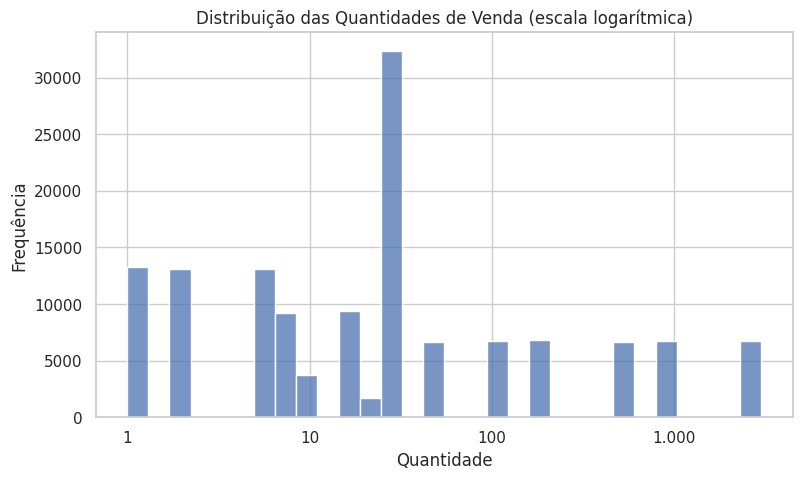

In [ ]:
# Distribuição da Quantidade (Histograma) - escala logarítmica para mostrar todas as vendas
plt.figure(figsize=(9, 5))
sns.histplot(df['Qnt.'], bins=30, log_scale=True)
plt.title('Distribuição das Quantidades de Venda (escala logarítmica)')
plt.xlabel('Quantidade')
plt.ylabel('Frequência')
plt.gca().xaxis.set_major_formatter(FuncFormatter(formato_milhar))
plt.show()

**Interpretação:** a maioria das vendas tem quantidade pequena (a mediana é 25 e o valor mais comum é 30), mas existem vendas de até 3.000. Com a escala logarítmica dá para ver tudo, sem cortar as vendas grandes. A quantidade depende da unidade (KG, SC, UN...), então não vamos comparar quantidade entre produtos diferentes.

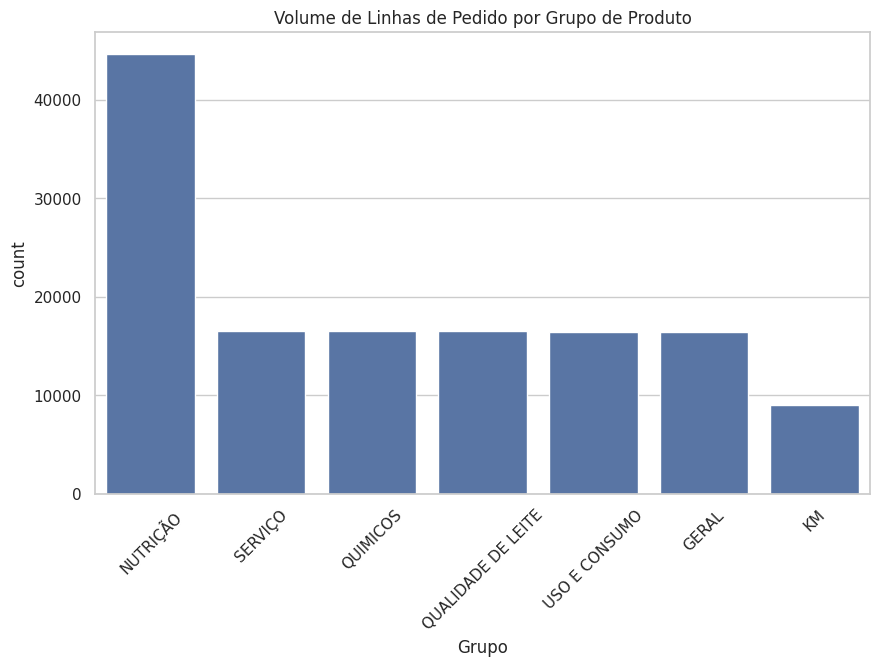

In [ ]:
# Frequência de Vendas por Categoria (Countplot)

plt.figure(figsize=(10, 6))
sns.countplot(x='Grupo', data=df, order=df['Grupo'].value_counts().index)
plt.title('Volume de Linhas de Pedido por Grupo de Produto')
plt.xticks(rotation=45)
plt.show()

**Interpretação:** `NUTRIÇÃO` é o grupo com mais linhas (cerca de 33%), seguido de cinco grupos com cerca de 12% cada e do `KM` (cerca de 7%). Mais linhas não quer dizer mais receita, mas veremos que `NUTRIÇÃO` também lidera em valor.

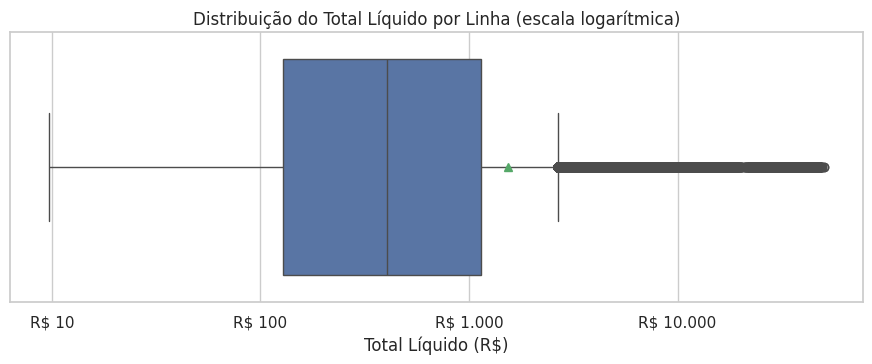

In [ ]:
# Identificação de Vendas Grandes (Boxplot) - escala logarítmica
plt.figure(figsize=(11, 3.5))
sns.boxplot(x=df['Total Líquido'], showmeans=True)
plt.xscale('log')
plt.title('Distribuição do Total Líquido por Linha (escala logarítmica)')
plt.xlabel('Total Líquido (R$)')
eixo_em_reais(plt.gca().xaxis)
plt.show()

**Interpretação:** metade das vendas fica entre R\$ 128 e R\$ 1.142 (mediana de R\$ 402). Os pontos à direita da caixa são as **vendas grandes**, que chegam a R\$ 50 mil. Na escala normal esse gráfico ficava "espremido" embaixo; na escala logarítmica dá para ver todas as vendas. O triângulo verde (média) fica acima da mediana, o que mostra que as vendas grandes puxam a média para cima.

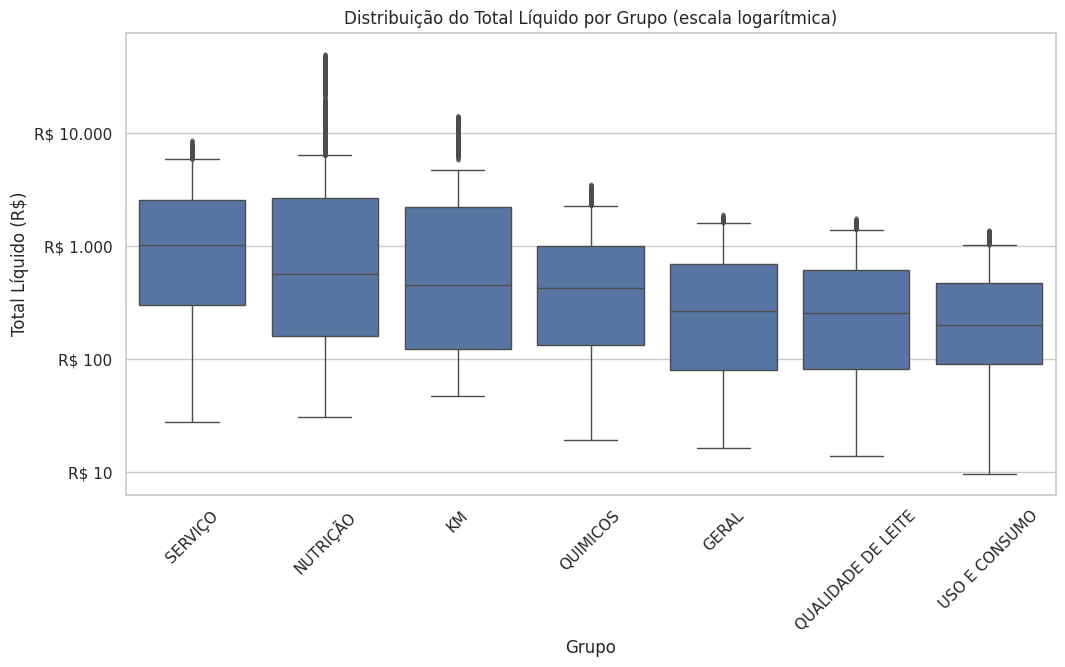

In [ ]:
# Distribuição do Total Líquido por Grupo (Boxplot) - todas as vendas, escala logarítmica
ordem = df.groupby('Grupo')['Total Líquido'].median().sort_values(ascending=False).index

plt.figure(figsize=(12, 6))
sns.boxplot(x='Grupo', y='Total Líquido', data=df, order=ordem, flierprops={'markersize': 2, 'alpha': 0.3})
plt.yscale('log')
plt.title('Distribuição do Total Líquido por Grupo (escala logarítmica)')
plt.xticks(rotation=45)
plt.ylabel('Total Líquido (R$)')
eixo_em_reais(plt.gca().yaxis)
plt.show()

**Interpretação:** agora mostramos todas as vendas, inclusive as grandes. `NUTRIÇÃO` e `KM` têm os pontos mais altos (vendas de até R\$ 50 mil e R\$ 14 mil) e cerca de 13% das linhas desses grupos ficam acima do limite da caixa. Já `GERAL` e `QUALIDADE DE LEITE` quase não têm vendas grandes. `SERVIÇO` tem a maior mediana (cerca de R\$ 1.016). Essas vendas grandes são reais e ficaram na análise.

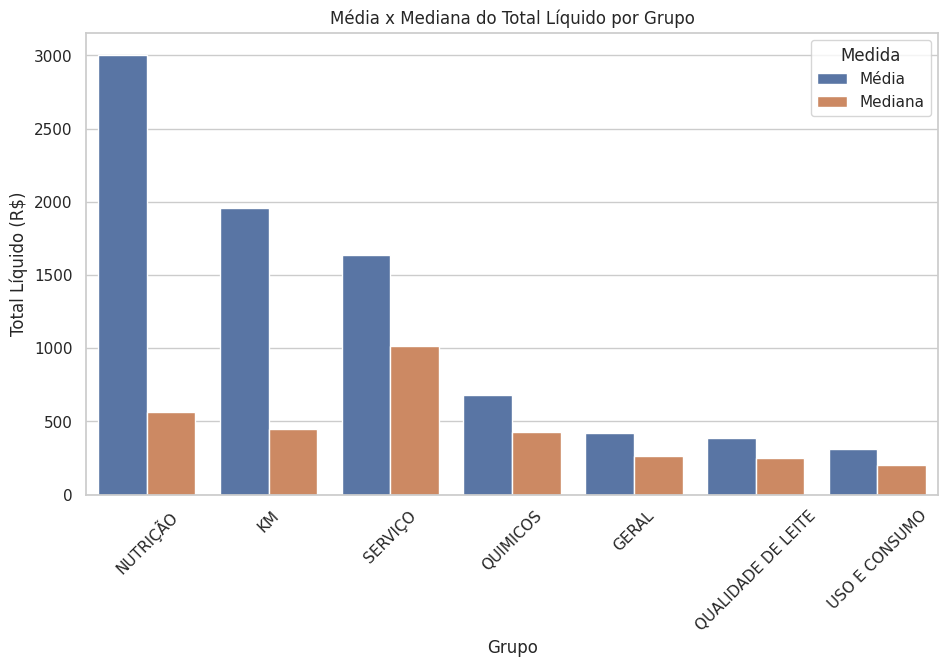

In [ ]:
# Média x Mediana do Total Líquido por Grupo (Barplot)
resumo_grupo = (df.groupby('Grupo')['Total Líquido']
                  .agg(Média='mean', Mediana='median')
                  .sort_values('Média', ascending=False)
                  .reset_index()
                  .melt(id_vars='Grupo', var_name='Medida', value_name='Total Líquido'))

plt.figure(figsize=(11, 6))
sns.barplot(data=resumo_grupo, x='Grupo', y='Total Líquido', hue='Medida')
plt.title('Média x Mediana do Total Líquido por Grupo')
plt.xticks(rotation=45)
plt.ylabel('Total Líquido (R$)')
plt.show()

**Interpretação:** em `NUTRIÇÃO` a média (cerca de R\$ 3.006) é muito maior que a mediana (cerca de R\$ 562), e em `KM` também (R\$ 1.961 contra R\$ 448). Isso acontece por causa das vendas grandes. Nos outros grupos as duas medidas ficam mais próximas. Por isso, para falar da venda típica, é melhor usar a **mediana**.

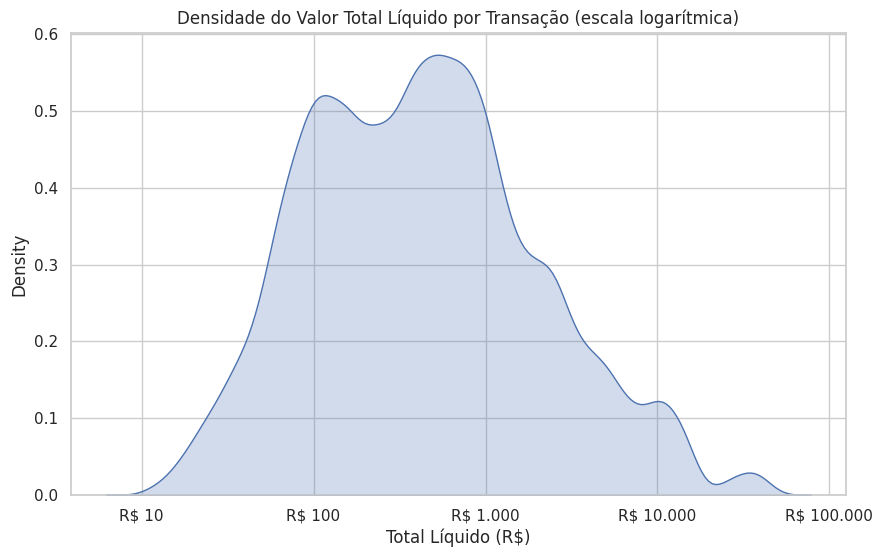

In [ ]:
# Densidade do Valor de Compras (KDE Plot) - escala logarítmica
plt.figure(figsize=(10, 6))
sns.kdeplot(df['Total Líquido'], fill=True, log_scale=True)
plt.title('Densidade do Valor Total Líquido por Transação (escala logarítmica)')
plt.xlabel('Total Líquido (R$)')
eixo_em_reais(plt.gca().xaxis)
plt.show()

**Interpretação:** o gráfico tem mais de um pico porque junta grupos com valores diferentes (itens baratos de uso e consumo e sacarias de nutrição). Antes cortávamos os 10% maiores valores para o gráfico ficar bonito, mas isso escondia as vendas grandes. Com a escala logarítmica não precisamos cortar nada.

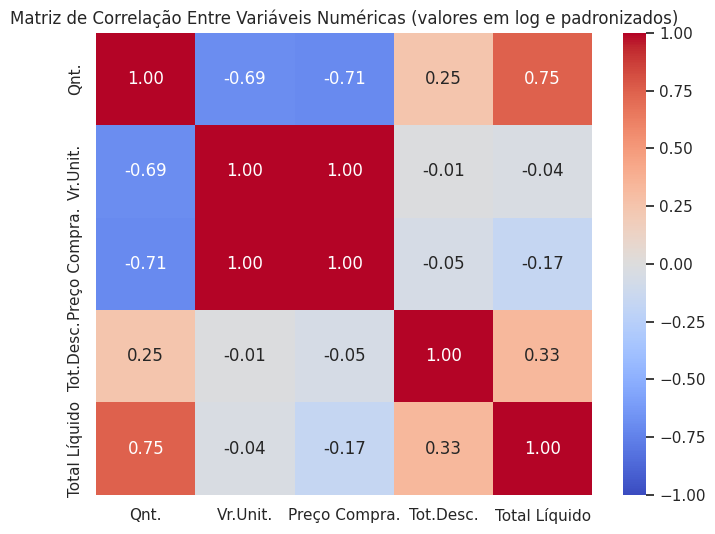

In [ ]:
# Matriz de Correlação das Variáveis Numéricas (Mapa de Calor)
# Usamos só as variáveis principais (antes eram 20, com códigos e valores repetidos)
colunas_corr = ['Qnt.', 'Vr.Unit.', 'Preço Compra.', 'Tot.Desc.', 'Total Líquido']

# log (para diminuir o efeito das vendas grandes) e StandardScaler (mesma escala)
valores = np.log1p(df[colunas_corr])
valores_padronizados = pd.DataFrame(StandardScaler().fit_transform(valores), columns=colunas_corr)

corr = valores_padronizados.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('Matriz de Correlação Entre Variáveis Numéricas (valores em log e padronizados)')
plt.show()

### Mapa de Calor

- Quanto mais fria (azul) a cor, menos relação entre as variáveis

- Quanto mais quente (vermelho) a cor, mais relação entre as variáveis

> O coeficiente de correlação entre cada par está escrito em cada "quadrado" no mapa

> Ele varia entre -1 e +1, sendo:

- +1: correlação positiva perfeita
- -1: correlação negativa perfeita
- 0: sem correlação entre as variáveis

**Interpretação:**

- `Vr.Unit.` e `Preço Compra.` (1,00): o preço de venda acompanha o custo, então as duas variáveis mostram a mesma informação.
- `Qnt.` e `Total Líquido` (0,75): o valor da venda é puxado principalmente pela quantidade.
- `Qnt.` e `Vr.Unit.` (-0,69): produtos baratos (vendidos em kg e sacos) saem em grande quantidade, e produtos caros saem em pouca.
- `Vr.Unit.` e `Total Líquido` (-0,04): o preço quase não explica o tamanho da venda, quem explica é a quantidade.
- `Tot.Desc.` tem relação fraca com as outras (no máximo 0,33).

Agora o mapa tem só 5 variáveis (antes eram 20, com códigos e valores repetidos) e dá para ler cada número. O log diminuiu o efeito das vendas grandes e o StandardScaler deixou as variáveis na mesma escala.

**Atenção para não confundir:** aqui o log foi aplicado **nos valores** (`np.log1p`, que é o log de 1 + valor; o "+ 1" evita erro quando o valor é zero, como no desconto). Nos gráficos anteriores o log era só no **desenho do eixo** e os valores não mudavam.

In [ ]:
# Tabela de Contingência (Crosstab)

# Cruza os dados de Grupos de Produtos com as Condições de Pagamento
tabela_cruzada = pd.crosstab(df['Grupo'], df['Condição'])
print("--- Preferência de Condição de Pagamento por Grupo ---")
display(tabela_cruzada)

--- Preferência de Condição de Pagamento por Grupo ---


Condição,1-A VISTA,2-30 DIAS,27-40 DIAS,29-50 DIAS,63-28 DIAS,66-7 DIAS,77-300/400/500 DIAS,81-100/200 DIAS,83-200,84-120 DIAS
Grupo,,,,,,,,,,
GERAL,1600,1636,1659,1606,1610,1625,1661,1677,1727,1613
KM,876,918,904,874,881,904,900,928,901,958
NUTRIÇÃO,4436,4494,4484,4497,4493,4446,4488,4361,4582,4374
QUALIDADE DE LEITE,1577,1649,1594,1723,1636,1714,1679,1636,1666,1587
QUIMICOS,1636,1595,1631,1615,1598,1705,1668,1659,1727,1669
SERVIÇO,1575,1617,1624,1670,1668,1723,1676,1677,1684,1620
USO E CONSUMO,1587,1705,1623,1591,1662,1695,1679,1579,1643,1677


**Interpretação:** as 10 condições de pagamento aparecem em proporções quase iguais (entre 9,5% e 10,6%) em todos os grupos. Ou seja, não existe uma condição preferida por grupo. Esse padrão tão igual acontece porque a base é simulada, então essa variável ajuda pouco nas análises.

### Evolução da receita no tempo

O gráfico de peso x receita foi trocado por gráficos de tempo, porque o nosso problema é **prever a demanda**, e para isso precisamos ver como as vendas mudam ao longo dos anos e dos meses.

,Receita,Pedidos,Ticket_Medio_Pedido
Ano,,,
2016,10261028.0,6812,1506.0
2017,11341235.0,7124,1592.0
2018,12889275.0,7752,1663.0
2019,14673720.0,8044,1824.0
2020,15506464.0,8464,1832.0
2021,19120153.0,9243,2069.0
2022,20354222.0,9696,2099.0
2023,24162168.0,10283,2350.0
2024,24954861.0,10934,2282.0


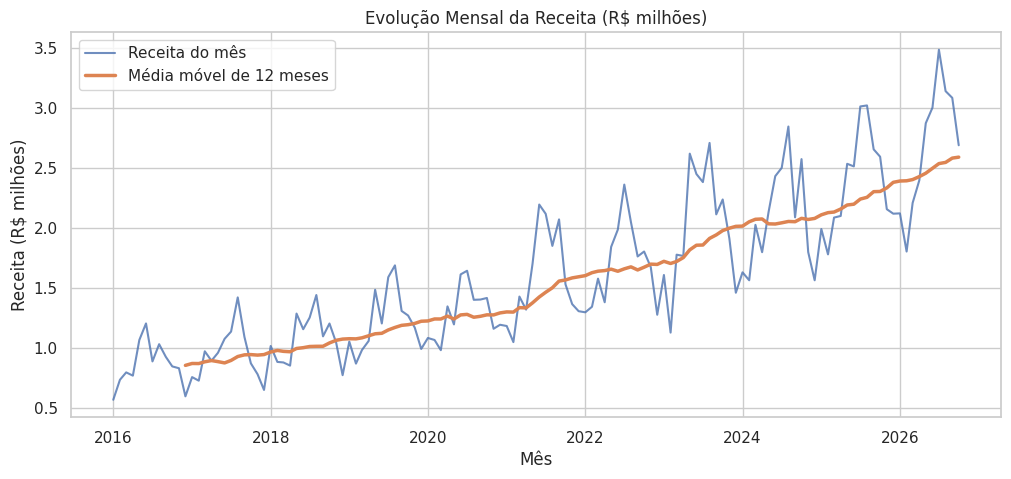

In [ ]:
# Receita e pedidos por ano
resumo_ano = df.groupby('Ano').agg(Receita=('Total Líquido', 'sum'), Pedidos=('Nº Ped.', 'nunique'))
resumo_ano['Ticket_Medio_Pedido'] = resumo_ano['Receita'] / resumo_ano['Pedidos']
display(resumo_ano.round(0))

# Receita por mês, com média móvel de 12 meses
receita_mes = df.groupby(df['Dt.Ped.'].dt.to_period('M'))['Total Líquido'].sum() / 1e6
receita_mes.index = receita_mes.index.to_timestamp()

plt.figure(figsize=(12, 5))
plt.plot(receita_mes.index, receita_mes.values, label='Receita do mês', alpha=0.8)
plt.plot(receita_mes.index, receita_mes.rolling(12).mean(), label='Média móvel de 12 meses', linewidth=2.5)
plt.title('Evolução Mensal da Receita (R$ milhões)')
plt.xlabel('Mês')
plt.ylabel('Receita (R$ milhões)')
plt.legend()
plt.show()

**Interpretação:** a receita cresce todos os anos, de cerca de R\$ 10,3 milhões em 2016 para cerca de R\$ 28,6 milhões em 2025 (aproximadamente 12% ao ano). O número de pedidos e o valor médio por pedido aumentaram. O ano de 2026 está incompleto (vai até outubro). Também se vê um **padrão que se repete todo ano**, com picos no meio do ano. Então existe **tendência de crescimento e sazonalidade**, e o modelo de previsão precisa considerar as duas coisas.

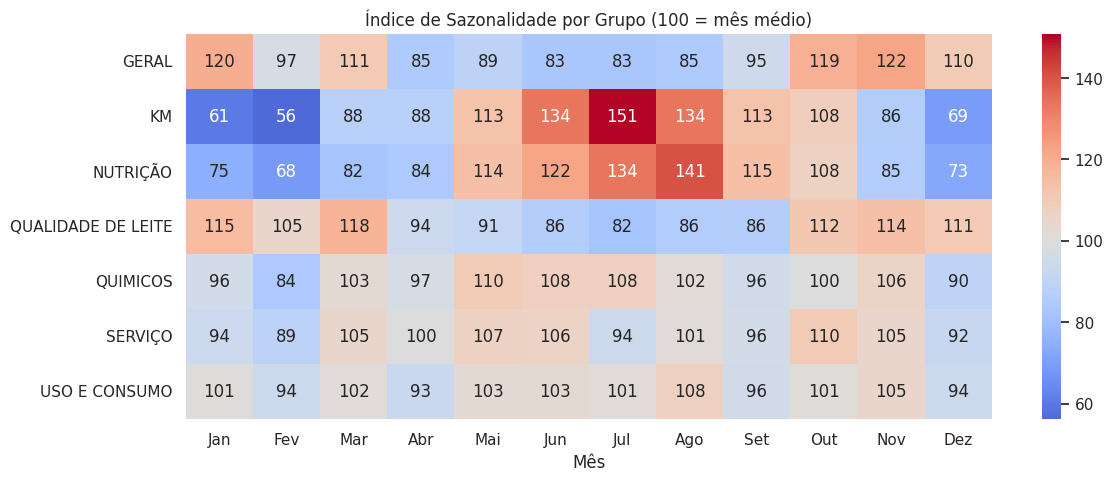

In [ ]:
# Sazonalidade por grupo: 100 = mês médio do grupo (só anos completos, de 2016 a 2025)
base_sazonal = df[df['Ano'] <= 2025]
pivo = base_sazonal.pivot_table(index='Grupo', columns='Mes', values='Total Líquido', aggfunc='sum')
indice_sazonal = pivo.div(pivo.mean(axis=1), axis=0) * 100

plt.figure(figsize=(13, 5))
sns.heatmap(indice_sazonal, annot=True, fmt='.0f', cmap='coolwarm', center=100,
            xticklabels=['Jan', 'Fev', 'Mar', 'Abr', 'Mai', 'Jun', 'Jul', 'Ago', 'Set', 'Out', 'Nov', 'Dez'])
plt.title('Índice de Sazonalidade por Grupo (100 = mês médio)')
plt.xlabel('Mês')
plt.ylabel('')
plt.show()

**Interpretação:** a sazonalidade é diferente em cada grupo:

- `NUTRIÇÃO` e `KM` vendem muito mais de **maio a setembro** e pouco em janeiro e fevereiro.
- `GERAL` e `QUALIDADE DE LEITE` fazem o contrário, com mais vendas de **outubro a janeiro**.
- `QUIMICOS`, `SERVIÇO` e `USO E CONSUMO` ficam perto de 100 o ano todo.

Para a empresa, isso quer dizer que o estoque de nutrição e mineralização precisa subir antes de maio, e o de `GERAL` e leite antes de outubro.

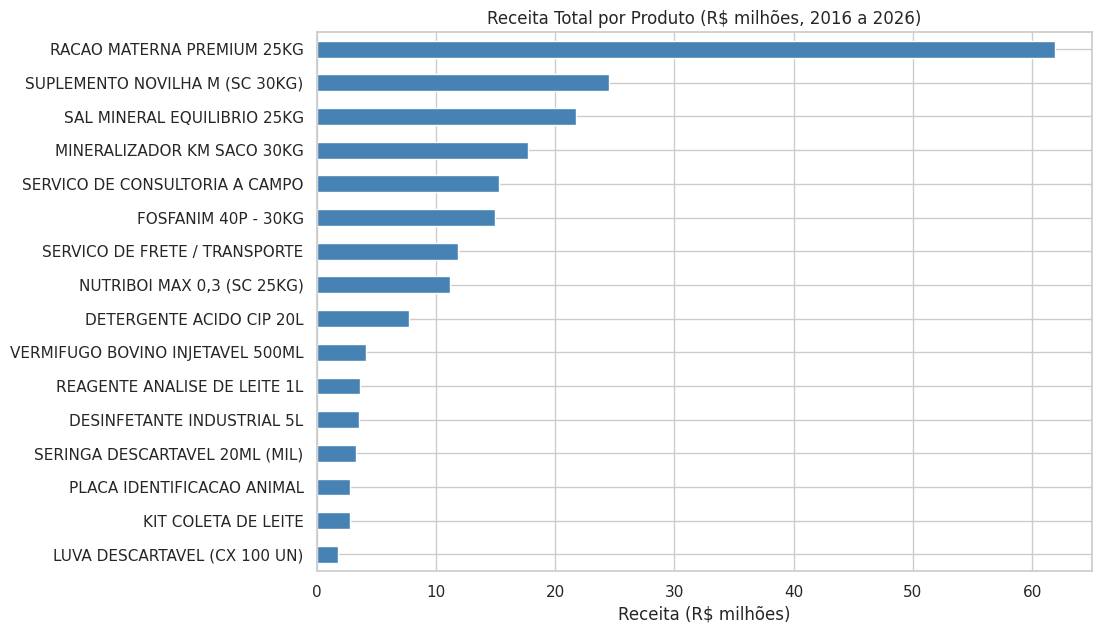

In [ ]:
# Receita total por produto
receita_produto = (df.groupby('Produto')['Total Líquido'].sum() / 1e6).sort_values()

plt.figure(figsize=(10, 7))
receita_produto.plot(kind='barh', color='steelblue')
plt.title('Receita Total por Produto (R$ milhões, 2016 a 2026)')
plt.xlabel('Receita (R$ milhões)')
plt.ylabel('')
plt.show()

**Interpretação:** a receita está concentrada em poucos produtos. A *Ração Materna Premium* sozinha é cerca de 30% da receita e os quatro primeiros produtos somam cerca de 60%. `NUTRIÇÃO` e `KM` juntos são cerca de 73% da receita. Esses produtos precisam de mais atenção no estoque, porque uma falta deles pesa muito.

In [ ]:
# Definindo o caminho de saída
caminho_saida_csv = '/content/drive/MyDrive/PI_DataScience/Gerador/vendas_limpa.csv'

# Salvando o DataFrame tratado (esse arquivo é a entrada do Data Warehouse)
df.to_csv(caminho_saida_csv, sep=';', index=False, encoding='utf-8')

print(f"Base limpa salva com sucesso em: {caminho_saida_csv}")
print(f"Linhas: {len(df):,} | Colunas: {df.shape[1]}")

Base limpa salva com sucesso em: /content/drive/MyDrive/PI_DataScience/Gerador/vendas_limpa.csv
Linhas: 136,052 | Colunas: 23


# Data Warehouse (DW)

Como a nossa base (vendas_limpa.csv) tem dados muito estruturados, vindos de um sistema de vendas (ERP/PDV), o **Data Warehouse** é a escolha certa. No projeto completo, a limpeza dos dados é feita em R (no pipeline de DevOps) e o CSV já tratado chega para a etapa de Big Data. Aqui, o arquivo `vendas_limpa.csv` faz esse papel e é a entrada do DW. Como os dados já chegam tratados, **não usamos Data Lake**.

- **Esquema Estrela (Star Schema):**

No sistema original, os dados ficam juntos em uma tabela grande. Para facilitar as consultas, dividimos essa tabela em um esquema estrela:
> Fato Vendas: tem as medidas do negócio (Quantidade, Total Líquido, Desconto) e as chaves das dimensões.

> Dimensões: Tempo (para ver a sazonalidade), Cliente, Produto (com Grupo), Vendedor e Cidade.

- **Processo ETL e OLAP:**

Extraímos os dados do CSV, transformamos nas tabelas de dimensões (sem repetições e com um ID para cada linha) e carregamos (Load) em um banco SQLite, que serve como DW no nosso projeto. Depois fazemos as operações OLAP: Slice (filtrar um grupo), Dice (cruzar variáveis), Drill-down (descer do ano para o mês) e Roll-up (subir do mês para o ano).

### Arquitetura do pipeline

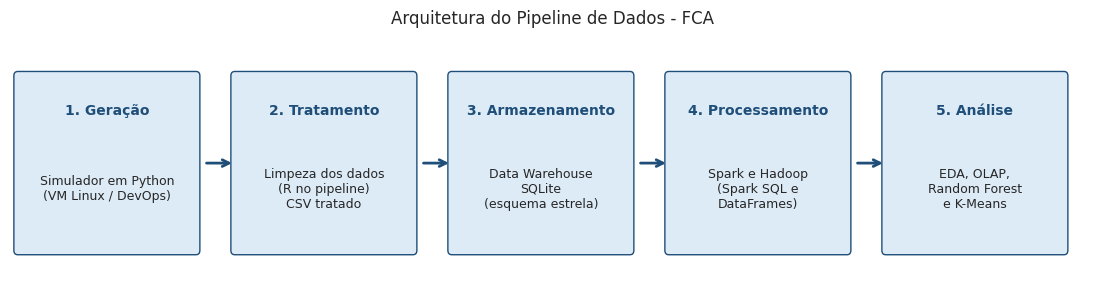

In [ ]:
# Diagrama da arquitetura do pipeline de dados
from matplotlib.patches import FancyBboxPatch

etapas = [
    ('1. Geração',       'Simulador em Python\n(VM Linux / DevOps)'),
    ('2. Tratamento',    'Limpeza dos dados\n(R no pipeline)\nCSV tratado'),
    ('3. Armazenamento', 'Data Warehouse\nSQLite\n(esquema estrela)'),
    ('4. Processamento', 'Spark e Hadoop\n(Spark SQL e\nDataFrames)'),
    ('5. Análise',       'EDA, OLAP,\nRandom Forest\ne K-Means'),
]

fig, ax = plt.subplots(figsize=(14, 3.4))
ax.set_xlim(0, len(etapas) * 2.8)
ax.set_ylim(0, 3)
ax.axis('off')

for i, (titulo, desc) in enumerate(etapas):
    x = i * 2.8 + 0.1
    ax.add_patch(FancyBboxPatch((x, 0.5), 2.3, 2.0, boxstyle='round,pad=0.05', facecolor='#DDEBF7', edgecolor='#1F4E79'))
    ax.text(x + 1.15, 2.1, titulo, ha='center', va='center', fontsize=10, fontweight='bold', color='#1F4E79')
    ax.text(x + 1.15, 1.2, desc, ha='center', va='center', fontsize=9)
    if i < len(etapas) - 1:
        ax.annotate('', xy=(x + 2.8, 1.5), xytext=(x + 2.4, 1.5), arrowprops=dict(arrowstyle='->', color='#1F4E79', lw=2))

plt.title('Arquitetura do Pipeline de Dados - FCA', fontsize=12)
plt.show()

In [ ]:
# Importações para o DW e Desenho do Esquema Estrela (Grafo)

import sqlite3
import os
import networkx as nx
import plotly.express as px
from ipywidgets import interact, widgets

In [ ]:
# Definindo o caminho do Data Warehouse
DW_PATH = '/content/drive/MyDrive/PI_DataScience/Gerador/datawarehouse_fca.db'

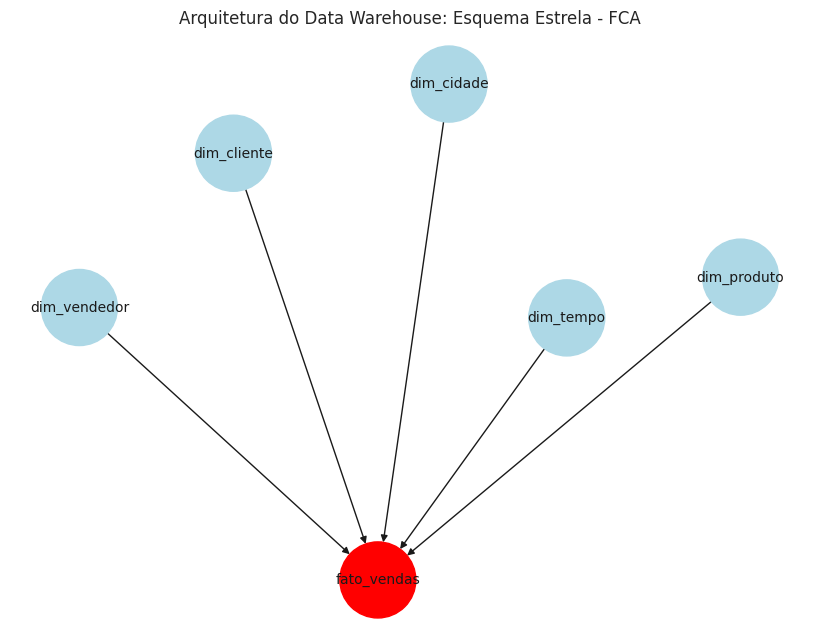

In [ ]:
# Criar o Grafo do Esquema Estrela para documentação visual
G = nx.DiGraph()

# Nó central (Fato)
G.add_node("fato_vendas", color="red")

# Nós de Dimensão
dimensoes = ["dim_tempo", "dim_cliente", "dim_produto", "dim_vendedor", "dim_cidade"]

for d in dimensoes:
    G.add_node(d, color="lightblue")
    G.add_edge(d, "fato_vendas")

# Plotar o diagrama da arquitetura
colors = [G.nodes[n]['color'] for n in G.nodes]
plt.figure(figsize=(8, 6))
nx.draw(G, with_labels=True, node_color=colors, node_size=3000, font_size=10, arrows=True)
plt.title("Arquitetura do Data Warehouse: Esquema Estrela - FCA")
plt.show()

# Transformação (ETL) - Criando Dimensões e Tabela Fato

In [ ]:
# Carregar a base limpa (as datas já foram tratadas na etapa de limpeza)
df_clean = pd.read_csv('/content/drive/MyDrive/PI_DataScience/Gerador/vendas_limpa.csv', sep=';', parse_dates=['Dt.Ped.'])

# Dimensão Produto (uma linha por produto)
dim_produto = df_clean[['IdProduto', 'Produto', 'Grupo', 'Tipo Venda', 'Un.']].drop_duplicates('IdProduto').copy()

# Dimensão Cliente (o Cód.Cliente repete para clientes diferentes, então criamos um ID novo)
dim_cliente = df_clean[['Cliente']].drop_duplicates().reset_index(drop=True)
dim_cliente['id_cliente'] = dim_cliente.index + 1

# Dimensão Vendedor (Criando um ID numérico)
dim_vendedor = df_clean[['Vendedor']].drop_duplicates().reset_index(drop=True)
dim_vendedor['id_vendedor'] = dim_vendedor.index + 1

# Dimensão Cidade (só os itens com nota fiscal têm cidade)
dim_cidade = df_clean[['Cidade', 'Estado']].dropna().drop_duplicates().reset_index(drop=True)
dim_cidade['id_cidade'] = dim_cidade.index + 1

# Dimensão Tempo
dim_tempo = pd.DataFrame({'Data_Completa': df_clean['Dt.Ped.'].dt.normalize().drop_duplicates().sort_values()})
dim_tempo['id_tempo'] = dim_tempo['Data_Completa'].dt.strftime('%Y%m%d').astype(int)
dim_tempo['Ano'] = dim_tempo['Data_Completa'].dt.year
dim_tempo['Mes'] = dim_tempo['Data_Completa'].dt.month
dim_tempo['Dia'] = dim_tempo['Data_Completa'].dt.day
dim_tempo['Trimestre'] = dim_tempo['Data_Completa'].dt.quarter
dim_tempo['Data_Completa'] = dim_tempo['Data_Completa'].dt.date

# Mesclar IDs gerados de volta na Fato Vendas
df_fato = df_clean.merge(dim_cliente, on='Cliente', how='left')
df_fato = df_fato.merge(dim_vendedor, on='Vendedor', how='left')
df_fato = df_fato.merge(dim_cidade, on=['Cidade', 'Estado'], how='left')
df_fato['id_tempo'] = df_fato['Dt.Ped.'].dt.strftime('%Y%m%d').astype(int)
df_fato['id_cidade'] = df_fato['id_cidade'].astype('Int64')

# Selecionar apenas chaves e métricas para a Fato
fato_vendas = df_fato[[
    'Nº Ped.', 'id_tempo', 'id_cliente', 'IdProduto', 'id_vendedor', 'id_cidade', 'Tipo_Documento',
    'Qnt.', 'Vr.Unit.', 'Total Líquido', 'Tot.Desc.', 'Preço Compra.'
]].copy()

print("ETL Concluído: Dimensões e Fato criadas com sucesso.")
print(f"fato_vendas: {len(fato_vendas):,} linhas | dim_produto: {len(dim_produto)} | dim_cliente: {len(dim_cliente)} | "
      f"dim_vendedor: {len(dim_vendedor)} | dim_cidade: {len(dim_cidade)} | dim_tempo: {len(dim_tempo)}")

ETL Concluído: Dimensões e Fato criadas com sucesso.
fato_vendas: 136,052 linhas | dim_produto: 16 | dim_cliente: 366 | dim_vendedor: 4 | dim_cidade: 25 | dim_tempo: 3732


# Carga (Load) - Salvando no Banco SQLite (Data Warehouse)

In [ ]:
# Criar a pasta do banco se não existir
pasta_dw = os.path.dirname(DW_PATH)
os.makedirs(pasta_dw, exist_ok=True)

# Manter no Data Warehouse (SQLite)
conn = sqlite3.connect(DW_PATH)

dim_cliente.to_sql('dim_cliente', conn, if_exists='replace', index=False)
dim_produto.to_sql('dim_produto', conn, if_exists='replace', index=False)
dim_vendedor.to_sql('dim_vendedor', conn, if_exists='replace', index=False)
dim_cidade.to_sql('dim_cidade', conn, if_exists='replace', index=False)
dim_tempo.to_sql('dim_tempo', conn, if_exists='replace', index=False)
fato_vendas.to_sql('fato_vendas', conn, if_exists='replace', index=False)

print(f"Tabelas carregadas com sucesso no Data Warehouse: {DW_PATH}")

Tabelas carregadas com sucesso no Data Warehouse: /content/drive/MyDrive/PI_DataScience/Gerador/datawarehouse_fca.db


In [ ]:
# Conferindo o Data Warehouse: o total do DW precisa ser igual ao total da base limpa
# (se uma dimensão tiver chave repetida, o JOIN duplica as linhas e o valor fica errado)
consulta_conferencia = '''
    SELECT COUNT(*) AS linhas, SUM(f."Total Líquido") AS total
    FROM fato_vendas f
    JOIN dim_tempo t ON f.id_tempo = t.id_tempo
    JOIN dim_produto p ON f.IdProduto = p.IdProduto
    JOIN dim_cliente c ON f.id_cliente = c.id_cliente
    JOIN dim_vendedor v ON f.id_vendedor = v.id_vendedor
'''
conferencia = pd.read_sql_query(consulta_conferencia, conn)

print(f"Linhas da base limpa: {len(df_clean):,} | linhas depois dos JOINs: {conferencia['linhas'][0]:,}")
print(f"Total da base: R$ {df_clean['Total Líquido'].sum():,.2f} | Total no DW: R$ {conferencia['total'][0]:,.2f}")
assert conferencia['linhas'][0] == len(df_clean) and np.isclose(conferencia['total'][0], df_clean['Total Líquido'].sum())
print("DW conferido: os JOINs não duplicaram nenhuma linha.")

Linhas da base limpa: 136,052 | linhas depois dos JOINs: 136,052
Total da base: R$ 208,632,683.35 | Total no DW: R$ 208,632,683.35
DW conferido: os JOINs não duplicaram nenhuma linha.


# Operações OLAP

O cubo OLAP é formado por **três dimensões** e uma **medida**. No nosso cubo as dimensões são **Ano**, **Grupo de Produto** e **Trimestre**, e a medida é a **Receita**. Cada bolinha do gráfico é uma "célula" do cubo (uma combinação de ano, grupo e trimestre). Quanto maior e mais clara a bolinha, maior a receita.

In [ ]:
# Cubo OLAP: busca no Data Warehouse a receita de cada combinação de Ano, Grupo e Trimestre
consulta_cubo = '''
    SELECT t.Ano, p.Grupo, t.Trimestre,
           SUM(f."Total Líquido") AS Receita,
           COUNT(DISTINCT f."Nº Ped.") AS Pedidos
    FROM fato_vendas f
    JOIN dim_tempo t ON f.id_tempo = t.id_tempo
    JOIN dim_produto p ON f.IdProduto = p.IdProduto
    GROUP BY t.Ano, p.Grupo, t.Trimestre
'''
cubo = pd.read_sql_query(consulta_cubo, conn)

print(f"O cubo tem {len(cubo)} células ({cubo['Ano'].nunique()} anos x {cubo['Grupo'].nunique()} grupos x {cubo['Trimestre'].nunique()} trimestres)")
cubo.head()

O cubo tem 308 células (11 anos x 7 grupos x 4 trimestres)


,Ano,Grupo,Trimestre,Receita,Pedidos
0,2016,GERAL,1,94868.62,293
1,2016,GERAL,2,66507.59,235
2,2016,GERAL,3,76426.99,263
3,2016,GERAL,4,85689.62,297
4,2016,KM,1,169856.95,116


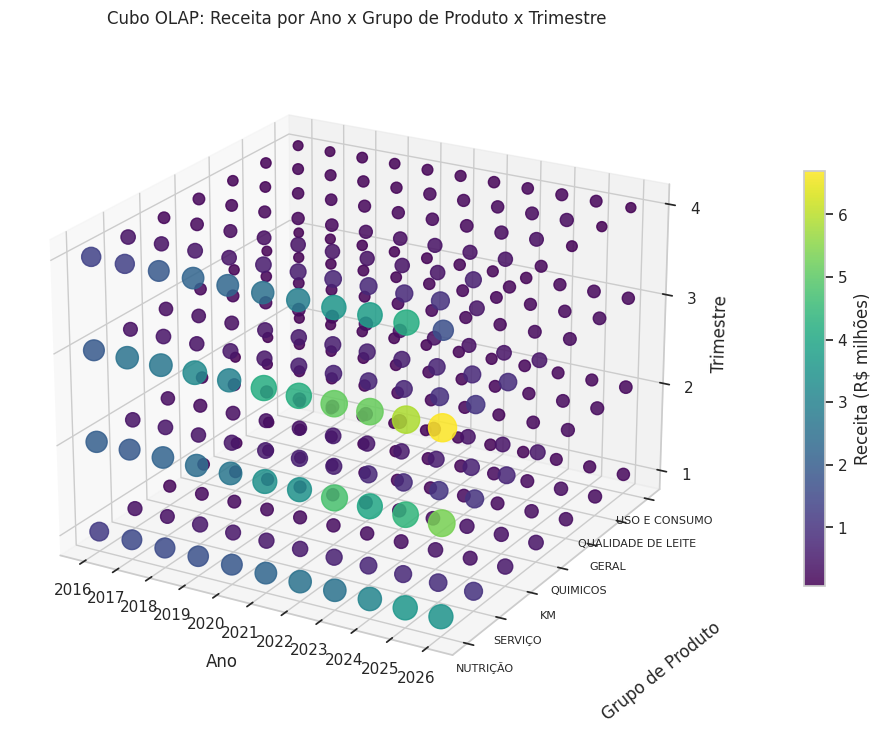

In [ ]:
# Gráfico do Cubo OLAP (3D)
# Grupos em ordem de receita (o grupo com mais receita fica em uma ponta do cubo)
grupos = list(cubo.groupby('Grupo')['Receita'].sum().sort_values(ascending=False).index)
cubo['Posicao_Grupo'] = cubo['Grupo'].map({grupo: i for i, grupo in enumerate(grupos)})

# Tamanho das bolinhas: usamos a raiz da receita para as pequenas não sumirem
tamanho = np.sqrt(cubo['Receita'])
tamanho = tamanho / tamanho.max() * 400 + 10

fig = plt.figure(figsize=(13, 9))
ax = fig.add_subplot(111, projection='3d')
pontos = ax.scatter(cubo['Ano'], cubo['Posicao_Grupo'], cubo['Trimestre'],
                    s=tamanho, c=cubo['Receita'] / 1e6, cmap='viridis', alpha=0.85)

ax.set_xlabel('Ano', labelpad=10)
ax.set_ylabel('Grupo de Produto', labelpad=45)
ax.set_zlabel('Trimestre')
ax.set_xticks(sorted(cubo['Ano'].unique()))
ax.set_yticks(range(len(grupos)))
ax.set_yticklabels(grupos, fontsize=8)
ax.set_zticks([1, 2, 3, 4])
ax.view_init(elev=22, azim=-60)

fig.colorbar(pontos, ax=ax, shrink=0.6, pad=0.1, label='Receita (R$ milhões)')
plt.title('Cubo OLAP: Receita por Ano x Grupo de Produto x Trimestre')
plt.show()

O gráfico acima é fixo. O gráfico abaixo é o **mesmo cubo, mas dá para girar** com o mouse e escolher a medida (Receita ou Número de Pedidos) na caixa de seleção.

In [ ]:
import plotly.graph_objects as go

# Tamanho das bolinhas (de 4 a 26) para cada medida
def tamanho_bolinha(valores):
    raiz = np.sqrt(valores)
    return 4 + raiz / raiz.max() * 22

medidas = ['Receita', 'Pedidos']
fig = go.Figure()

for i, medida in enumerate(medidas):
    fig.add_trace(go.Scatter3d(
        x=cubo['Ano'], y=cubo['Grupo'], z=cubo['Trimestre'],
        mode='markers',
        name=medida,
        visible=(i == 0),
        marker=dict(size=tamanho_bolinha(cubo[medida]), color=cubo[medida], colorscale='Viridis',
                    opacity=0.85, showscale=True, colorbar=dict(title=medida)),
        hovertemplate='Ano: %{x}<br>Grupo: %{y}<br>Trimestre: %{z}<br>' + medida + ': %{marker.color:,.0f}<extra></extra>'
    ))

# Caixa de seleção para trocar a medida
botoes = [dict(label=medida, method='update', args=[{'visible': [m == medida for m in medidas]}])
          for medida in medidas]

fig.update_layout(
    title='Cubo OLAP (interativo): gire com o mouse e troque a medida',
    height=650,
    updatemenus=[dict(buttons=botoes, direction='down', x=0.02, y=0.98)],
    scene=dict(
        xaxis=dict(title='Ano', dtick=1),
        yaxis=dict(title='Grupo de Produto', categoryorder='array', categoryarray=grupos),
        zaxis=dict(title='Trimestre', dtick=1),
    ),
)
fig.show()

**Interpretação:** o cubo mostra a receita de cada combinação de ano, grupo e trimestre. As bolinhas maiores e mais claras são as de `NUTRIÇÃO` (depois `SERVIÇO` e `KM`), nos anos mais recentes e no 2º e 3º trimestres, o que confirma a sazonalidade e o crescimento que vimos na EDA.

### Slice, Dice, Drill-down e Roll-up

Agora cada operação do OLAP separada, usando o Data Warehouse.

In [ ]:
# ROLL-UP: sobe do mês para o ano (receita total por ano)
rollup = pd.read_sql_query('''
    SELECT t.Ano, ROUND(SUM(f."Total Líquido"), 0) AS Receita
    FROM fato_vendas f JOIN dim_tempo t ON f.id_tempo = t.id_tempo
    GROUP BY t.Ano ORDER BY t.Ano
''', conn)
print('ROLL-UP: receita por ano')
display(rollup)

# DRILL-DOWN: desce do ano de 2025 para o trimestre e depois para o mês
drill_trimestre = pd.read_sql_query('''
    SELECT t.Trimestre, ROUND(SUM(f."Total Líquido"), 0) AS Receita
    FROM fato_vendas f JOIN dim_tempo t ON f.id_tempo = t.id_tempo
    WHERE t.Ano = 2025 GROUP BY t.Trimestre ORDER BY t.Trimestre
''', conn)
print('\nDRILL-DOWN: receita de 2025 por trimestre')
display(drill_trimestre)

drill_mes = pd.read_sql_query('''
    SELECT t.Mes, ROUND(SUM(f."Total Líquido"), 0) AS Receita
    FROM fato_vendas f JOIN dim_tempo t ON f.id_tempo = t.id_tempo
    WHERE t.Ano = 2025 GROUP BY t.Mes ORDER BY t.Mes
''', conn)
print('DRILL-DOWN: receita de 2025 por mês')
display(drill_mes.T)

ROLL-UP: receita por ano


,Ano,Receita
0,2016,10261028.0
1,2017,11341235.0
2,2018,12889275.0
3,2019,14673720.0
4,2020,15506464.0
5,2021,19120153.0
6,2022,20354222.0
7,2023,24162168.0
8,2024,24954861.0
9,2025,28563919.0



DRILL-DOWN: receita de 2025 por trimestre


,Trimestre,Receita
0,1,5857899.0
1,2,7147949.0
2,3,8688887.0
3,4,6869184.0


DRILL-DOWN: receita de 2025 por mês


,0,1,2,3,4,5,6,7,8,9,10,11
Mes,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,10.0,11.0,12.0
Receita,1991323.0,1779985.0,2086591.0,2100176.0,2534680.0,2513092.0,3012685.0,3020987.0,2655215.0,2593686.0,2156431.0,2119067.0


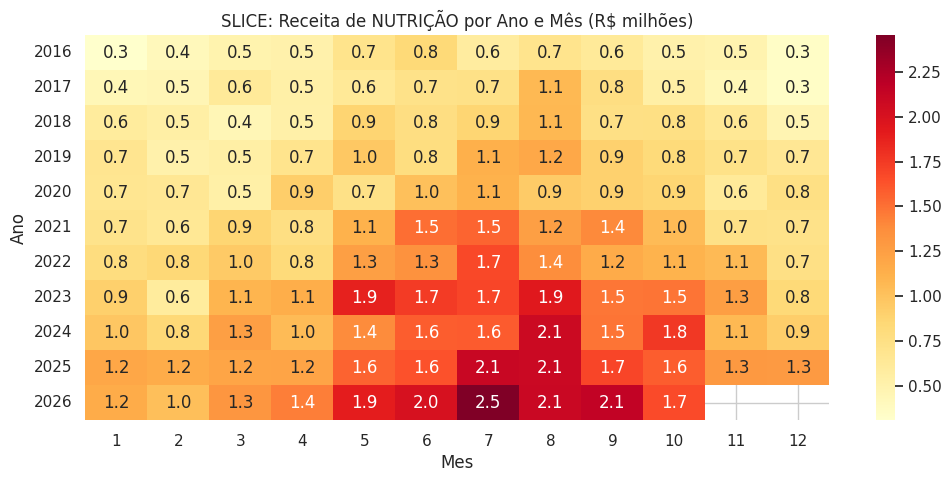

In [ ]:
# SLICE: fixa uma dimensão (Grupo = NUTRIÇÃO) e olha a receita por ano e mês
slice_nutricao = pd.read_sql_query('''
    SELECT t.Ano, t.Mes, SUM(f."Total Líquido") AS Receita
    FROM fato_vendas f
    JOIN dim_tempo t ON f.id_tempo = t.id_tempo
    JOIN dim_produto p ON f.IdProduto = p.IdProduto
    WHERE p.Grupo = 'NUTRIÇÃO'
    GROUP BY t.Ano, t.Mes
''', conn)

tabela_slice = slice_nutricao.pivot(index='Ano', columns='Mes', values='Receita') / 1e6

plt.figure(figsize=(12, 5))
sns.heatmap(tabela_slice, annot=True, fmt='.1f', cmap='YlOrRd')
plt.title('SLICE: Receita de NUTRIÇÃO por Ano e Mês (R$ milhões)')
plt.show()

In [ ]:
# DICE: escolhe uma parte do cubo (2 grupos e os anos de 2023 a 2025) e cruza com o trimestre
dice = pd.read_sql_query('''
    SELECT p.Grupo, t.Trimestre, ROUND(SUM(f."Total Líquido") / 1000000, 2) AS Receita_Milhoes
    FROM fato_vendas f
    JOIN dim_tempo t ON f.id_tempo = t.id_tempo
    JOIN dim_produto p ON f.IdProduto = p.IdProduto
    WHERE p.Grupo IN ('NUTRIÇÃO', 'KM') AND t.Ano BETWEEN 2023 AND 2025
    GROUP BY p.Grupo, t.Trimestre
''', conn)

print('DICE: receita (R$ milhões) de NUTRIÇÃO e KM, de 2023 a 2025, por trimestre')
display(dice.pivot(index='Grupo', columns='Trimestre', values='Receita_Milhoes'))

DICE: receita (R$ milhões) de NUTRIÇÃO e KM, de 2023 a 2025, por trimestre


Trimestre,1,2,3,4
Grupo,,,,
KM,1.02,1.76,2.08,1.37
NUTRIÇÃO,9.23,13.19,16.16,11.48


**Interpretação:** o **slice** mostra que a receita de `NUTRIÇÃO` é mais forte de maio a setembro e cresce de um ano para o outro. O **dice** confirma que, em `NUTRIÇÃO` e `KM`, o 2º e o 3º trimestres vendem bem mais que o 1º. O **roll-up** mostra o crescimento anual e o **drill-down** mostra como 2025 se divide por trimestre e por mês.

# Interface OLAP Interativa (Drill-down e Roll-up)

In [ ]:
# Dicionário de relações para a interface SQL Interativa
olap_dimensoes_fca = {
    'Ano (Roll-up)': 't.Ano',
    'Mes (Drill-down)': 't.Mes',
    'Grupo de Produto': 'p.Grupo',
    'Vendedor': 'v.Vendedor',
    'Estado (Slice)': 'c.Estado'
}

dim1_drop = widgets.Dropdown(options=olap_dimensoes_fca.keys(), description='Dimensão 1:')
dim2_drop = widgets.Dropdown(options=['Nenhuma'] + list(olap_dimensoes_fca.keys()), description='Dimensão 2:')

def consulta_olap_fca(dim1, dim2):
    col1 = olap_dimensoes_fca[dim1]
    col2 = olap_dimensoes_fca[dim2] if dim2 != 'Nenhuma' else None

    select_clause = f"{col1} AS dim1"
    group_clause = "dim1"

    if col2:
        select_clause += f", {col2} AS dim2"
        group_clause += ", dim2"

    query = f"""
        SELECT
            {select_clause},
            SUM(f."Total Líquido") AS faturamento_total
        FROM fato_vendas f
        JOIN dim_tempo t ON f.id_tempo = t.id_tempo
        JOIN dim_produto p ON f.IdProduto = p.IdProduto
        LEFT JOIN dim_vendedor v ON f.id_vendedor = v.id_vendedor
        LEFT JOIN dim_cidade c ON f.id_cidade = c.id_cidade
        GROUP BY {group_clause}
        ORDER BY faturamento_total DESC
        LIMIT 20
    """

    df_resultado = pd.read_sql_query(query, conn)

    plt.figure(figsize=(12, 6))
    if col2:
        sns.barplot(data=df_resultado, x='dim1', y='faturamento_total', hue='dim2')
        plt.legend(title=dim2, bbox_to_anchor=(1.05, 1), loc='upper left')
    else:
        sns.barplot(data=df_resultado, x='dim1', y='faturamento_total', hue='dim1', palette='viridis', legend=False)

    plt.title(f'OLAP: Faturamento por {dim1}' + (f' cruzado com {dim2}' if col2 else ''))
    plt.xlabel(dim1)
    plt.ylabel('Faturamento Total (R$)')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

# Exibir interface
interact(consulta_olap_fca, dim1=dim1_drop, dim2=dim2_drop)

interactive(children=(Dropdown(description='Dimensão 1:', options=('Ano (Roll-up)', 'Mes (Drill-down)', 'Grupo…

<function __main__.consulta_olap_fca(dim1, dim2)>

Se as caixas de seleção acima não aparecerem, execute a célula novamente. Abaixo, dois exemplos já prontos (sem precisar das caixas).

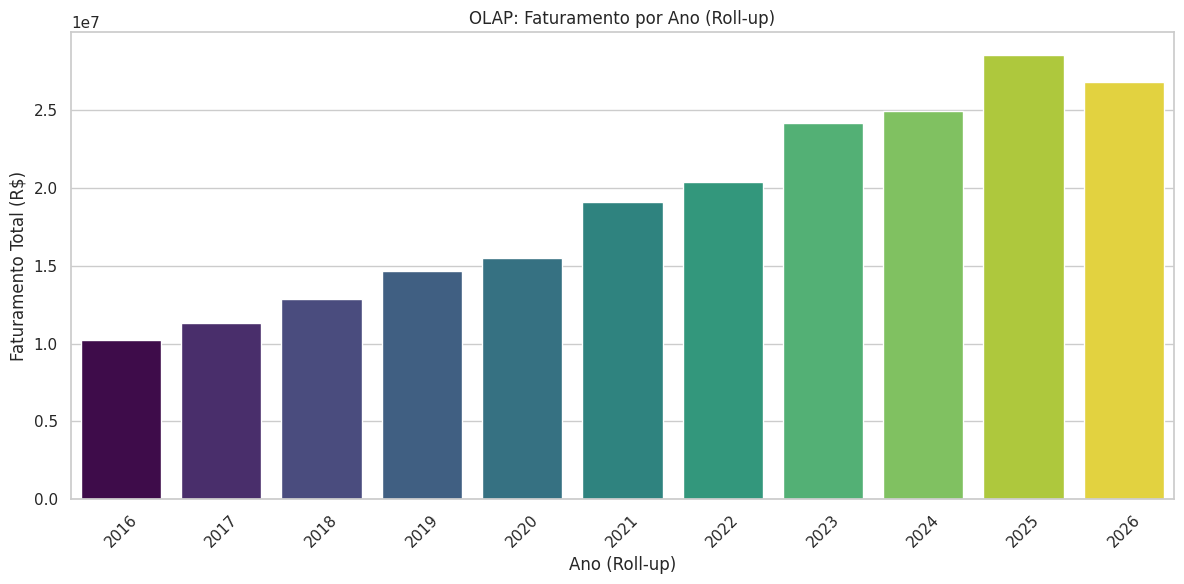

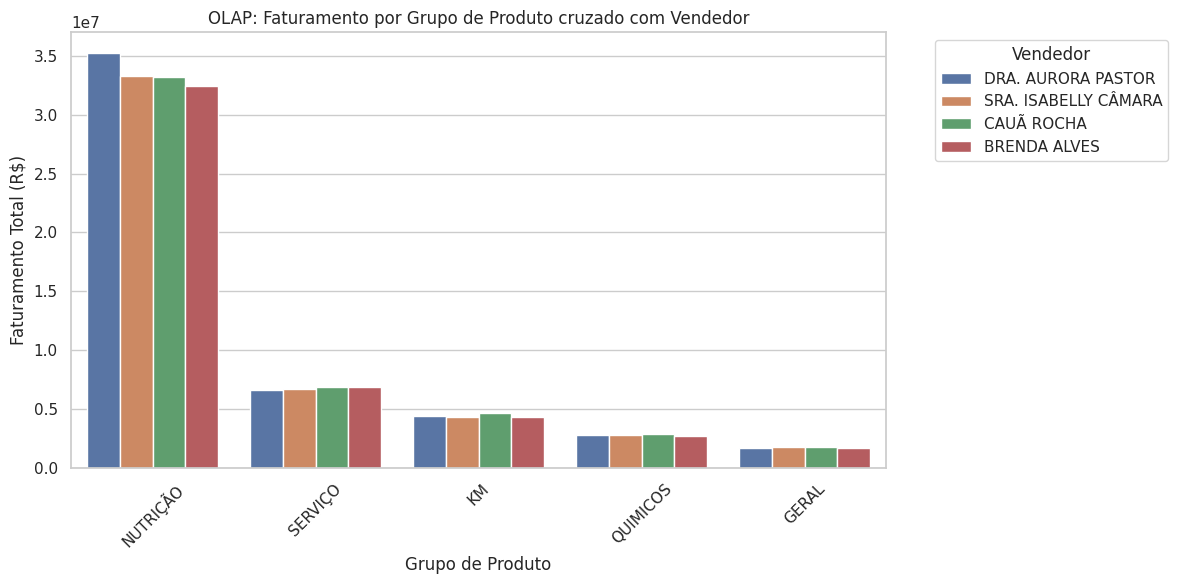

In [ ]:
# Exemplo 1: faturamento por ano (Roll-up)
consulta_olap_fca('Ano (Roll-up)', 'Nenhuma')

# Exemplo 2: faturamento por grupo de produto e vendedor
consulta_olap_fca('Grupo de Produto', 'Vendedor')

# Data Mining e Machine Learning

Para o projeto, utilizamos a **Regressão** _(para prever a demanda mensal e auxiliar na reposição de estoque)_ e no **Agrupamento** _(para entender o perfil de compra dos clientes)_.

A classificação, embora útil, não foi incluída pois as duas técnicas selecionadas já respondem integralmente à pergunta central de negócio do projeto: "Como prever a demanda mensal por produto e identificar o comportamento de compra dos produtores rurais para otimizar a reposição de estoque, evitando rupturas em períodos de alta e sobras de estoque na F.C.A. Serviços Pecuários?"

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.cluster import KMeans
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, silhouette_score
import datetime

# Carregando os Dados Limpos (recarregando para garantir que estamos partindo do mesmo ponto)
df_ml = pd.read_csv('/content/drive/MyDrive/PI_DataScience/Gerador/vendas_limpa.csv', sep=';', parse_dates=['Dt.Ped.'])
print(f"Base carregada: {len(df_ml):,} linhas | de {df_ml['Dt.Ped.'].min():%d/%m/%Y} até {df_ml['Dt.Ped.'].max():%d/%m/%Y}")

Base carregada: 136,052 linhas | de 01/01/2016 até 31/10/2026


## Modelo de Regressão - Random Forest (Previsão de Demanda)

**O que queremos prever:** a demanda mensal (soma da `Qnt.`) de cada produto.

**Variáveis usadas:** o produto, o ano, o mês, a demanda do mês anterior (`Lag_1`), a demanda do mesmo mês no ano anterior (`Lag_12`) e a média dos 3 meses anteriores (`Media_Movel_3`).

> Não usamos o valor vendido (`Total Líquido`) do próprio mês, porque esse valor só fica conhecido quando o mês acaba e já tem a quantidade dentro dele. Se usássemos, o modelo "colaria" a resposta e o resultado ficaria bom demais.

**Treino e teste:** separamos pelo tempo. Treino de 2016 a 2024 e teste de 2025 até outubro de 2026, como se estivéssemos prevendo o mês seguinte.

In [ ]:
# Engenharia de Variáveis para Regressão (Agrupando a demanda por mês e produto)
df_ml['Ano_Mes'] = df_ml['Dt.Ped.'].dt.to_period('M')
mensal = df_ml.groupby(['Ano_Mes', 'IdProduto'])['Qnt.'].sum().rename('Demanda_Mensal').reset_index()

# Tabela completa com todos os meses e todos os produtos (mês sem venda = demanda zero)
meses = pd.period_range(df_ml['Ano_Mes'].min(), df_ml['Ano_Mes'].max(), freq='M')
produtos = sorted(df_ml['IdProduto'].unique())
grade = pd.MultiIndex.from_product([meses, produtos], names=['Ano_Mes', 'IdProduto']).to_frame(index=False)
df_regressao = grade.merge(mensal, on=['Ano_Mes', 'IdProduto'], how='left').fillna({'Demanda_Mensal': 0})
df_regressao = df_regressao.sort_values(['IdProduto', 'Ano_Mes']).reset_index(drop=True)

df_regressao['Ano'] = df_regressao['Ano_Mes'].dt.year
df_regressao['Mes'] = df_regressao['Ano_Mes'].dt.month

# Histórico de cada produto (sempre de meses que já passaram)
demanda_produto = df_regressao.groupby('IdProduto')['Demanda_Mensal']
df_regressao['Lag_1'] = demanda_produto.shift(1)
df_regressao['Lag_12'] = demanda_produto.shift(12)
df_regressao['Media_Movel_3'] = demanda_produto.transform(lambda s: s.shift(1).rolling(3).mean())

# Tira os primeiros meses, que ainda não têm histórico
df_regressao = df_regressao.dropna(subset=['Lag_1', 'Lag_12', 'Media_Movel_3']).reset_index(drop=True)
print(f"Linhas (produto x mês) usadas no modelo: {len(df_regressao):,}")
df_regressao.head()

Linhas (produto x mês) usadas no modelo: 1,888


,Ano_Mes,IdProduto,Demanda_Mensal,Ano,Mes,Lag_1,Lag_12,Media_Movel_3
0,2017-01,1000,15765,2017,1,19520.0,23025.0,31996.666667
1,2017-02,1000,23030,2017,2,15765.0,27290.0,22265.000000
2,2017-03,1000,42590,2017,3,23030.0,29945.0,19438.333333
3,2017-04,1000,35765,2017,4,42590.0,32300.0,27128.333333
4,2017-05,1000,33920,2017,5,35765.0,34530.0,33795.000000


In [ ]:
# Preparação para Treino e Teste (Regressão)
# Separamos os dados pelo tempo, como orientado, para simular uma previsão real
variaveis_num = ['Ano', 'Mes', 'Lag_1', 'Lag_12', 'Media_Movel_3']
variaveis_cat = ['IdProduto']

X_reg = df_regressao[variaveis_num + variaveis_cat]
y_reg = df_regressao['Demanda_Mensal']

# Divisão Temporal: Treino (2016-2024), Teste (2025-2026)
treino_mask = df_regressao['Ano'] <= 2024
X_train_reg, y_train_reg = X_reg[treino_mask], y_reg[treino_mask]
X_test_reg, y_test_reg = X_reg[~treino_mask], y_reg[~treino_mask]

print(f"Treino: {len(X_train_reg):,} linhas | Teste: {len(X_test_reg):,} linhas")

Treino: 1,536 linhas | Teste: 352 linhas


In [ ]:
# Pipeline de Processamento (StandardScaler nos números e OneHotEncoder no produto)
preprocessor_reg = ColumnTransformer(transformers=[
    ('num', Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                            ('scaler', StandardScaler())]), variaveis_num),
    ('cat', OneHotEncoder(handle_unknown='ignore'), variaveis_cat),
])

In [ ]:
# Criação e Treinamento do Modelo Random Forest
model_rf = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)

pipeline_reg = Pipeline(steps=[
    ('preprocessor', preprocessor_reg),
    ('regressor', model_rf)
])

pipeline_reg.fit(X_train_reg, y_train_reg)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Ano', 'Mes', 'Lag_1',
                                                   'Lag_12', 'Media_Movel_3']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['IdProduto'])])),
                ('regressor',
                 RandomForestRegressor(n_estimators=200, n_jobs=-1,
                                       random_state=42))])

In [ ]:
# Avaliação do Modelo (comparando com duas previsões simples)
def avaliar(y_real, y_prev):
    return {
        'MAE': mean_absolute_error(y_real, y_prev),
        'RMSE': np.sqrt(mean_squared_error(y_real, y_prev)),
        'R²': r2_score(y_real, y_prev),
        'Erro (% da demanda)': np.abs(y_real - y_prev).sum() / y_real.sum() * 100,
    }

y_pred_reg = pipeline_reg.predict(X_test_reg)

# Previsão simples 1: repetir a demanda do mesmo mês do ano anterior
previsao_ano_anterior = X_test_reg['Lag_12']

# Previsão simples 2: média do produto naquele mês (calculada só com o treino)
media_mes = df_regressao[treino_mask].groupby(['IdProduto', 'Mes'])['Demanda_Mensal'].mean()
previsao_media = df_regressao[~treino_mask].apply(lambda r: media_mes.get((r['IdProduto'], r['Mes']), np.nan), axis=1)

comparacao = pd.DataFrame({
    'Random Forest': avaliar(y_test_reg, y_pred_reg),
    'Mesmo mês do ano anterior': avaliar(y_test_reg, previsao_ano_anterior),
    'Média histórica do mês': avaliar(y_test_reg, previsao_media),
}).T.round(2)

print("--- Avaliação do Modelo de Regressão (Random Forest) ---")
display(comparacao)

erro_rf = comparacao.loc['Random Forest', 'Erro (% da demanda)']
print(f"\nO modelo erra em média {erro_rf:.1f}% da demanda real nos {len(y_test_reg)} meses de teste.")

# O Random Forest é adequado pois consegue capturar relações não-lineares, como a sazonalidade e o histórico de cada produto.

--- Avaliação do Modelo de Regressão (Random Forest) ---


,MAE,RMSE,R²,Erro (% da demanda)
Random Forest,3477.59,6933.79,0.94,16.76
Mesmo mês do ano anterior,4156.79,8091.68,0.91,20.03
Média histórica do mês,5030.71,9589.29,0.88,24.24



O modelo erra em média 16.8% da demanda real nos 352 meses de teste.


Variáveis mais importantes:
Lag_12            0.572
Media_Movel_3     0.204
Lag_1             0.176
Mes               0.023
Ano               0.014
IdProduto_1039    0.002
dtype: float64


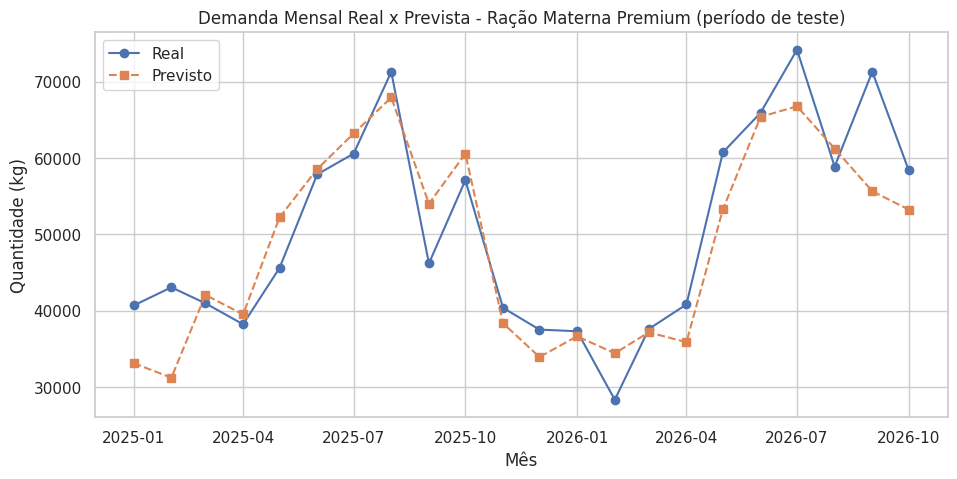

In [ ]:
# Quais variáveis mais ajudaram o modelo?
nomes = pipeline_reg.named_steps['preprocessor'].get_feature_names_out()
importancias = pd.Series(pipeline_reg.named_steps['regressor'].feature_importances_, index=nomes)
importancias.index = [n.replace('num__', '').replace('cat__', '') for n in importancias.index]
print("Variáveis mais importantes:")
print(importancias.sort_values(ascending=False).head(6).round(3))

# Real x Previsto de um produto (Ração Materna Premium)
produto_exemplo = df_ml.loc[df_ml['Produto'].str.startswith('RACAO'), 'IdProduto'].iloc[0]
teste = df_regressao[~treino_mask].copy()
teste['Previsto'] = y_pred_reg
teste_produto = teste[teste['IdProduto'] == produto_exemplo]

plt.figure(figsize=(11, 5))
plt.plot(teste_produto['Ano_Mes'].dt.to_timestamp(), teste_produto['Demanda_Mensal'], marker='o', label='Real')
plt.plot(teste_produto['Ano_Mes'].dt.to_timestamp(), teste_produto['Previsto'], marker='s', linestyle='--', label='Previsto')
plt.title('Demanda Mensal Real x Prevista - Ração Materna Premium (período de teste)')
plt.xlabel('Mês')
plt.ylabel('Quantidade (kg)')
plt.legend()
plt.show()

**Interpretação:** o modelo erra em média cerca de 16,8% da demanda no período de teste, contra 20,0% da previsão "mesmo mês do ano anterior" e 24,2% da "média histórica do mês". Ou seja, ele melhora as duas previsões simples, mas a melhora é moderada, porque boa parte da sazonalidade já aparece nelas. A variável mais importante foi a demanda do mesmo mês no ano anterior (`Lag_12`, cerca de 57%), seguida da média dos 3 meses anteriores e da demanda do mês anterior. No gráfico, a linha prevista acompanha a subida da demanda no meio do ano e a queda no começo do ano. Com dados reais o erro tende a ser maior, porque a base simulada é mais regular.

# Modelo de Agrupamento - K-Means (Segmentação de Clientes)

In [ ]:
# Engenharia de Variáveis para Agrupamento (Clientes)
# Usamos o nome do cliente (padronizado), porque o Cód.Cliente se repete para clientes diferentes
data_referencia = df_ml['Dt.Ped.'].max()

df_clientes = df_ml.groupby('Cliente').agg(
    Total_Comprado=('Total Líquido', 'sum'),
    Frequencia_Compras=('Nº Ped.', 'nunique'),
    Ticket_Medio=('Total Líquido', 'mean'),
    Primeira_Compra=('Dt.Ped.', 'min'),
).reset_index()
df_clientes['Meses_Como_Cliente'] = ((data_referencia - df_clientes['Primeira_Compra']).dt.days / 30.4).round(1)

# Preparação dos Dados (Agrupamento)
X_cluster = df_clientes[['Total_Comprado', 'Frequencia_Compras', 'Ticket_Medio']]
print(f"Clientes para agrupar: {len(df_clientes)}")

Clientes para agrupar: 366


**Sobre as vendas grandes:** aqui **não** usamos o log. Os clientes que compram muito são justamente o grupo que queremos encontrar, então não faz sentido "diminuir" a diferença deles. Usamos só o StandardScaler para as três variáveis ficarem na mesma escala.

In [ ]:
# Pipeline de Processamento Numérico (Padronização é crucial para K-Means)
numeric_transformer_cluster = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

preprocessor_cluster = ColumnTransformer(transformers=[
    ('num', numeric_transformer_cluster, ['Total_Comprado', 'Frequencia_Compras', 'Ticket_Medio'])
])

# Processando os dados antes do K-Means
X_cluster_processed = preprocessor_cluster.fit_transform(X_cluster)

### Quantos grupos (clusters) usar?

Para escolher o número de clusters testamos de 2 a 8 grupos e olhamos duas coisas:

- **Método do Cotovelo:** mostra o quanto os grupos ficam "apertados" (inércia). Quanto menor, melhor, mas a partir de certo ponto a melhora fica pequena. Esse ponto é o "cotovelo".
- **Silhouette:** mostra o quanto os grupos estão bem separados. Quanto mais perto de 1, melhor.

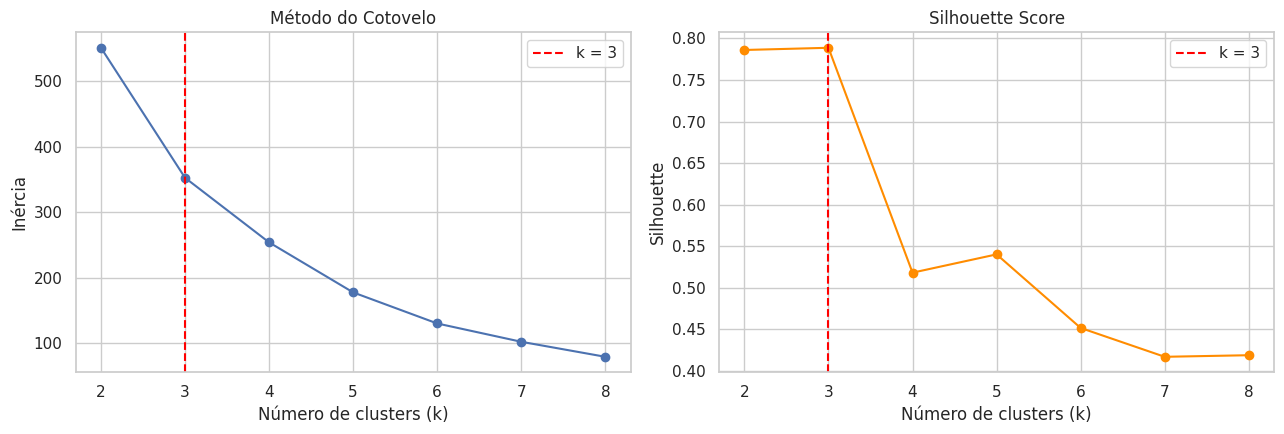

,k,Inércia,Silhouette,Queda da inércia (%)
0,2,551.5,0.786,NaN
1,3,352.7,0.789,-36.0
2,4,254.0,0.518,-28.0
3,5,177.5,0.540,-30.1
4,6,130.0,0.452,-26.8
5,7,102.0,0.417,-21.5
6,8,79.0,0.419,-22.5


In [ ]:
# Método do Cotovelo e Silhouette para k de 2 até 8
valores_k = list(range(2, 9))
inercias = []
silhuetas = []

for k in valores_k:
    modelo_teste = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_cluster_processed)
    inercias.append(modelo_teste.inertia_)
    silhuetas.append(silhouette_score(X_cluster_processed, modelo_teste.labels_))

fig, eixos = plt.subplots(1, 2, figsize=(13, 4.5))

eixos[0].plot(valores_k, inercias, marker='o')
eixos[0].axvline(3, color='red', linestyle='--', label='k = 3')
eixos[0].set_title('Método do Cotovelo')
eixos[0].set_xlabel('Número de clusters (k)')
eixos[0].set_ylabel('Inércia')
eixos[0].legend()

eixos[1].plot(valores_k, silhuetas, marker='o', color='darkorange')
eixos[1].axvline(3, color='red', linestyle='--', label='k = 3')
eixos[1].set_title('Silhouette Score')
eixos[1].set_xlabel('Número de clusters (k)')
eixos[1].set_ylabel('Silhouette')
eixos[1].legend()

plt.tight_layout()
plt.show()

# Tabela com os valores
tabela_k = pd.DataFrame({'k': valores_k, 'Inércia': np.round(inercias, 1), 'Silhouette': np.round(silhuetas, 3)})
tabela_k['Queda da inércia (%)'] = (tabela_k['Inércia'].pct_change() * 100).round(1)
display(tabela_k)

**Por que 3 clusters?** O silhouette é o maior com 3 clusters (0,789) e cai bastante com 4 clusters (0,518). No cotovelo, a inércia cai 36% de 2 para 3 clusters e depois a queda fica menor, então o cotovelo não é muito marcado e por isso usamos o silhouette junto. Com 2 clusters o silhouette é parecido (0,786), mas os 6 clientes novos ficam misturados com os clientes regulares. Com 3 clusters eles formam um grupo próprio, com comportamento diferente. Por isso escolhemos k = 3.

In [ ]:
# Aplicando o Modelo com k = 3 (escolhido pelo cotovelo e pelo silhouette)
k_clientes = 3
model_kmeans = KMeans(n_clusters=k_clientes, random_state=42, n_init=10)

df_clientes['Cluster'] = model_kmeans.fit_predict(X_cluster_processed)

In [ ]:
# Avaliação do Agrupamento (Silhouette Score)
score = silhouette_score(X_cluster_processed, df_clientes['Cluster'])
print(f"--- Avaliação do K-Means (Segmentação de Clientes) ---")
print(f"Silhouette Score (Coesão/Separação dos Clusters): {score:.4f}")

--- Avaliação do K-Means (Segmentação de Clientes) ---
Silhouette Score (Coesão/Separação dos Clusters): 0.7887


In [ ]:
# Interpretando os Grupos
print("\n--- Perfil dos Grupos de Clientes ---")
perfil = df_clientes.groupby('Cluster').agg(
    Clientes=('Cliente', 'size'),
    Total_Comprado_Medio=('Total_Comprado', 'mean'),
    Pedidos_Medio=('Frequencia_Compras', 'mean'),
    Ticket_Medio=('Ticket_Medio', 'mean'),
    Meses_Como_Cliente=('Meses_Como_Cliente', 'mean'),
).round(1)
perfil['% da Receita'] = (df_clientes.groupby('Cluster')['Total_Comprado'].sum() / df_clientes['Total_Comprado'].sum() * 100).round(1)
display(perfil)

# O K-Means foi escolhido por ser o algoritmo para segmentação comportamental separando a base em perfis distintos e acionáveis.


--- Perfil dos Grupos de Clientes ---


,Clientes,Total_Comprado_Medio,Pedidos_Medio,Ticket_Medio,Meses_Como_Cliente,% da Receita
Cluster,,,,,,
0,19,3690531.2,1787.2,1517.4,115.7,33.6
1,6,98200.9,15.8,5731.5,8.4,0.3
2,341,404467.4,193.4,1605.0,84.5,66.1


**Interpretação:** o K-Means separou três perfis:

- **Grandes produtores:** 19 clientes, com mais de 1.700 pedidos em média e cerca de 116 meses de relacionamento. Representam cerca de 34% da receita.
- **Clientes regulares:** 341 clientes, com cerca de 193 pedidos em média. Representam cerca de 66% da receita.
- **Clientes novos:** 6 clientes com cerca de 8 meses de relacionamento, poucos pedidos e ticket alto (cerca de R\$ 5,7 mil). Ainda quase não pesam na receita.

Os clientes novos não são "ocasionais": são recentes e ainda não tiveram tempo de comprar mais vezes. Os grupos separam os clientes principalmente pelo tamanho da compra, porque o total comprado e a frequência andam juntos. Os clientes grandes não são erro, eles são o grupo que queríamos encontrar.

In [ ]:
# Conectando ML aos Insights de Negócio
cluster_premium = perfil['Total_Comprado_Medio'].idxmax()
cluster_novos = perfil['Meses_Como_Cliente'].idxmin()
cluster_regular = [c for c in perfil.index if c not in (cluster_premium, cluster_novos)][0]

print("--- Insights Direcionados e Tomada de Decisão ---")

print(f"\n1. Ação para Grandes Produtores (Cluster {cluster_premium}):")
print(f"   São {perfil.loc[cluster_premium, 'Clientes']:.0f} clientes e representam {perfil.loc[cluster_premium, '% da Receita']:.1f}% da receita.")
print("   Decisão: dar prioridade de estoque nos produtos de NUTRIÇÃO e KM, principalmente antes de maio. Programas de fidelidade e reposição programada evitam perder esses clientes por falta de produto.")

print(f"\n2. Ação para Clientes Novos (Cluster {cluster_novos}):")
print(f"   São {perfil.loc[cluster_novos, 'Clientes']:.0f} clientes com cerca de {perfil.loc[cluster_novos, 'Meses_Como_Cliente']:.0f} meses de casa e ticket médio de R$ {perfil.loc[cluster_novos, 'Ticket_Medio']:,.0f}.")
print("   Decisão: acompanhar de perto e incentivar a recompra, porque podem virar clientes regulares.")

print(f"\n3. Ação para Clientes Regulares (Cluster {cluster_regular}):")
print(f"   São {perfil.loc[cluster_regular, 'Clientes']:.0f} clientes e representam {perfil.loc[cluster_regular, '% da Receita']:.1f}% da receita.")
print("   Decisão: manter o atendimento e fazer campanhas por época do ano (ex: mineralização antes da seca).")

print("\n4. Reposição Baseada na Regressão:")
print("   A previsão de demanda mensal do Random Forest pode alimentar um painel de compras. Quando o estoque da FCA for integrado (hoje não está na base):")
print("   - Se Previsão de Qnt. > Estoque Atual + Em Trânsito: Disparar alerta de reposição.")
print("   - Se Previsão de Qnt. < Estoque Atual: Risco de sobra de estoque, avaliar uma promoção.")

--- Insights Direcionados e Tomada de Decisão ---

1. Ação para Grandes Produtores (Cluster 0):
   São 19 clientes e representam 33.6% da receita.
   Decisão: dar prioridade de estoque nos produtos de NUTRIÇÃO e KM, principalmente antes de maio. Programas de fidelidade e reposição programada evitam perder esses clientes por falta de produto.

2. Ação para Clientes Novos (Cluster 1):
   São 6 clientes com cerca de 8 meses de casa e ticket médio de R$ 5,732.
   Decisão: acompanhar de perto e incentivar a recompra, porque podem virar clientes regulares.

3. Ação para Clientes Regulares (Cluster 2):
   São 341 clientes e representam 66.1% da receita.
   Decisão: manter o atendimento e fazer campanhas por época do ano (ex: mineralização antes da seca).

4. Reposição Baseada na Regressão:
   A previsão de demanda mensal do Random Forest pode alimentar um painel de compras. Quando o estoque da FCA for integrado (hoje não está na base):
   - Se Previsão de Qnt. > Estoque Atual + Em Trânsito: D

# Processamento de Big Data com Hadoop e Spark

Nesta etapa, a análise foi adaptada ao ecossistema de Big Data, preparando a arquitetura da F.C.A. Serviços Pecuários para lidar com volumes maiores de dados.

- **Hadoop (MapReduce e YARN):** o processamento distribuído foi **simulado em Python** para mostrar a lógica. O MapReduce (funções map, shuffle e reduce) conta os itens vendidos por Estado, e o YARN representa a fila de tarefas (jobs), como o cálculo do ticket médio por grupo de produto. O HDFS e o Hive são explicados no papel que teriam na arquitetura, pois não temos um cluster Hadoop de verdade neste ambiente.

- **Apache Spark (SQL e DataFrames API):** o PySpark processa os dados em memória. Com o Spark SQL, filtramos e ordenamos os dados para achar os 10 produtos com maior receita. Com a API de DataFrames, calculamos o volume e o faturamento por Fornecedor, que ajudam a priorizar as compras.

- **Escalabilidade da Solução:** em um cenário real, os dados sairiam do CSV e seriam guardados no HDFS em formato Parquet, divididos por ano e mês. Assim o Spark leria só as partes necessárias (por exemplo, só o mês de maior demanda) e gastaria menos tempo e recursos. No final desta parte mostramos isso funcionando.

# Hadoop (MapReduce, YARN, HDFS e Hive)

In [ ]:
# Hadoop: Papel do HDFS, YARN, MapReduce e Hive na arquitetura

# - HDFS: Armazenamento distribuído. Guarda os arquivos brutos de vendas da F.C.A. distribuindo-os em blocos para evitar perda de dados.
# - Hive: Funciona como um Data Warehouse no ecossistema, permitindo usar SQL para consultar dados no HDFS.
# - MapReduce: Processamento em lotes dividido em mapeamento, embaralhamento e redução.
# - YARN: Gerenciador de recursos que orquestra a fila e a execução das tarefas (jobs) no cluster.


# MAPREDUCE - Contar a quantidade de vendas realizadas por Estado (demanda regional)
def mapper_fca(linhas):
    # Mapper: identifica o estado de cada venda e cria o par (Estado, 1)
    pares = []
    for linha in linhas:
        if pd.notna(linha):
            pares.append((str(linha).strip(), 1))
    return pares

def shuffle_fca(mapped_data):
    # Shuffle: agrupa todas as ocorrências de cada Estado
    agrupado = {}
    for chave, valor in mapped_data:
        if chave not in agrupado:
            agrupado[chave] = []
        agrupado[chave].append(valor)
    return agrupado

def reducer_fca(agrupado):
    # Reducer: processa o agrupamento somando os totais
    return {chave: sum(valores) for chave, valores in agrupado.items()}

In [ ]:
# Executando a simulação do MapReduce com a coluna 'Estado'
dados_entrada = df_ml['Estado'].dropna().tolist()
mapeado = mapper_fca(dados_entrada)
agrupado = shuffle_fca(mapeado)
resultado_mr = reducer_fca(agrupado)

print("[MapReduce] Quantidade de itens com nota fiscal por Estado (só os itens com NF têm Estado):")
print(resultado_mr)
print("-" * 50)

[MapReduce] Quantidade de itens com nota fiscal por Estado (só os itens com NF têm Estado):
{'MA': 7818, 'BA': 5271, 'SC': 2574, 'AM': 2503, 'RS': 5070, 'DF': 2450, 'CE': 2580, 'SP': 5063, 'PB': 2561, 'RJ': 2591, 'ES': 2630, 'PR': 5037, 'PI': 2524, 'MG': 2501, 'PA': 2489, 'RO': 2603, 'RN': 2591, 'AP': 2564, 'GO': 2578}
--------------------------------------------------


In [ ]:
# YARN - Lista para armazenar a execução dos jobs
jobs = []

def enviar_job(nome, funcao):
    # YARN simulando a alocação e início de um Job
    print(f"[YARN] Iniciando job: {nome}")
    resultado = funcao()
    jobs.append({'nome': nome, 'status': 'finalizado'})
    return resultado

def job_ticket_medio_grupo():
    # Job analítico: Calcula o ticket médio por Grupo de Produto
    return df_ml.groupby('Grupo')['Total Líquido'].mean().round(2).to_dict()

In [ ]:
# Solicitando a execução do Job
resultado_yarn = enviar_job("Calcular Ticket Médio por Grupo", job_ticket_medio_grupo)

print("\nResultado do Job:")
for grupo, media in resultado_yarn.items():
    print(f"Grupo {grupo}: R$ {media}")

print("\n[YARN] Histórico de jobs:")
for job in jobs:
    print(f"{job['nome']} - {job['status']}")

[YARN] Iniciando job: Calcular Ticket Médio por Grupo

Resultado do Job:
Grupo GERAL: R$ 418.04
Grupo KM: R$ 1961.09
Grupo NUTRIÇÃO: R$ 3005.55
Grupo QUALIDADE DE LEITE: R$ 387.74
Grupo QUIMICOS: R$ 681.12
Grupo SERVIÇO: R$ 1638.39
Grupo USO E CONSUMO: R$ 310.81

[YARN] Histórico de jobs:
Calcular Ticket Médio por Grupo - finalizado


# Processamento Distribuído com PySpark e Spark SQL

In [ ]:
# Spark: DataFrames e Spark SQL com seleção, filtro, agrupamento, ordenação e indicadores.

from pyspark.sql import SparkSession
from pyspark.sql import functions as F

In [ ]:
# Cria ou recupera a sessão Spark
spark = SparkSession.builder.appName("FCA_Estoque_Spark").getOrCreate()
spark.sparkContext.setLogLevel("ERROR")
print(f"Spark iniciado. Versão: {spark.version}\n")

Spark iniciado. Versão: 4.0.5



In [ ]:
# Convertendo para Spark só as colunas que vamos usar (os números continuam como números)
# Os textos vazios viram None para o Spark entender como nulo
colunas_spark = ['Dt.Ped.', 'Produto', 'Grupo', 'Tipo Venda', 'Fornecedor', 'Estado', 'Qnt.', 'Total Líquido']
pdf_spark = df_ml[colunas_spark].copy()
for col in ['Produto', 'Grupo', 'Tipo Venda', 'Fornecedor', 'Estado']:
    pdf_spark[col] = pdf_spark[col].astype(object).where(pdf_spark[col].notna(), None)

df_spark = spark.createDataFrame(pdf_spark)
df_spark.printSchema()

root
 |-- Dt.Ped.: timestamp (nullable = true)
 |-- Produto: string (nullable = true)
 |-- Grupo: string (nullable = true)
 |-- Tipo Venda: string (nullable = true)
 |-- Fornecedor: string (nullable = true)
 |-- Estado: string (nullable = true)
 |-- Qnt.: long (nullable = true)
 |-- Total Líquido: double (nullable = true)



In [ ]:
# Criando uma View Temporária para permitir consultas usando Spark SQL
df_spark.createOrReplaceTempView("vendas_fca")

In [ ]:
# SPARK SQL - Seleção, Filtro, Agrupamento e Ordenação
# Tiramos só os serviços (não são produtos de estoque). Os produtos de representação ficam na análise
query_sql = '''
    SELECT
        `Produto`,
        SUM(`Qnt.`) AS Demanda_Total,
        CAST(SUM(`Total Líquido`) AS DECIMAL(18, 2)) AS Receita_Total
    FROM vendas_fca
    WHERE `Tipo Venda` <> 'SERVIÇOS' AND `Total Líquido` > 0
    GROUP BY `Produto`
    ORDER BY Receita_Total DESC
    LIMIT 10
'''
print("[Spark SQL] Top 10 Produtos (sem serviços) com Maior Receita:")
resultado_sql = spark.sql(query_sql)
resultado_sql.show(truncate=False)

[Spark SQL] Top 10 Produtos (sem serviços) com Maior Receita:
+--------------------------------+-------------+-------------+
|Produto                         |Demanda_Total|Receita_Total|
+--------------------------------+-------------+-------------+
|RACAO MATERNA PREMIUM 25KG      |5525510      |61907143.20  |
|SUPLEMENTO NOVILHA M (SC 30KG)  |5389415      |24467970.05  |
|SAL MINERAL EQUILIBRIO 25KG     |5436565      |21701635.90  |
|MINERALIZADOR KM SACO 30KG      |5586960      |17736075.90  |
|FOSFANIM 40P - 30KG             |5414070      |14946734.65  |
|NUTRIBOI MAX 0,3 (SC 25KG)      |5501935      |11189181.10  |
|DETERGENTE ACIDO CIP 20L        |101175       |7728103.87   |
|VERMIFUGO BOVINO INJETAVEL 500ML|101816       |4107196.65   |
|REAGENTE ANALISE DE LEITE 1L    |63239        |3635717.75   |
|DESINFETANTE INDUSTRIAL 5L      |101997       |3512395.86   |
+--------------------------------+-------------+-------------+



In [ ]:
# SPARK DATAFRAMES API - Indicadores para reposição de estoque agrupados por Fornecedor
print("[Spark DataFrames] Indicadores de Vendas e Demanda por Fornecedor:")
indicadores_df = (
    df_spark
    .select("Fornecedor", "`Qnt.`", "`Total Líquido`")
    .filter(F.col("Fornecedor").isNotNull() & (F.col("Fornecedor") != 'NÃO INFORMADO'))
    .groupBy("Fornecedor")
    .agg(
        F.sum("`Qnt.`").alias("Total_Unidades_Vendidas"),
        F.sum("`Total Líquido`").cast("decimal(18,2)").alias("Faturamento_Total"),
        F.round(F.avg("`Total Líquido`"), 2).alias("Ticket_Medio")
    )
    .orderBy(F.col("Faturamento_Total").desc())
    .limit(10)
)
indicadores_df.show(truncate=False)

[Spark DataFrames] Indicadores de Vendas e Demanda por Fornecedor:
+-----------------------------+-----------------------+-----------------+------------+
|Fornecedor                   |Total_Unidades_Vendidas|Faturamento_Total|Ticket_Medio|
+-----------------------------+-----------------------+-----------------+------------+
|MONTENEGRO PEREIRA S/A EIRELI|5628193                |31058009.40      |1548.72     |
|ANDRADE LTDA                 |5761855                |30337091.94      |1534.27     |
|CÂMARA ME                    |5621173                |30293541.43      |1522.44     |
|BORGES S.A. LTDA             |5575910                |30184211.12      |1506.87     |
|SILVA REZENDE E FILHOS ME    |5487820                |29869775.12      |1509.79     |
+-----------------------------+-----------------------+-----------------+------------+



In [ ]:
# ESCALABILIDADE: salvar em Parquet dividido por Ano e Mês e ler só uma parte
# (em um cenário real o caminho seria no HDFS, por exemplo: hdfs://namenode/fca/vendas)
caminho_parquet = '/content/fca_vendas_parquet'

df_particionado = (
    df_spark
    .select(F.col("`Dt.Ped.`").alias("Data_Pedido"), "Produto", "Grupo",
            F.col("`Qnt.`").alias("Qnt"), F.col("`Total Líquido`").alias("Total_Liquido"))
    .withColumn("Ano", F.year("Data_Pedido"))
    .withColumn("Mes", F.month("Data_Pedido"))
)
df_particionado.write.mode("overwrite").partitionBy("Ano", "Mes").parquet(caminho_parquet)

# Lendo só julho de 2025: o Spark abre apenas essa pasta (veja o PartitionFilters no plano)
leitura = spark.read.parquet(caminho_parquet).filter((F.col("Ano") == 2025) & (F.col("Mes") == 7))
print("Plano de execução:")
leitura.explain()
print(f"Linhas lidas (jul/2025): {leitura.count():,} de {df_spark.count():,} no total")
leitura.groupBy("Grupo").agg(F.round(F.sum("Total_Liquido"), 2).alias("Receita")).orderBy(F.col("Receita").desc()).show()

Plano de execução:
== Physical Plan ==
*(1) ColumnarToRow
+- FileScan parquet [Data_Pedido#67,Produto#68,Grupo#69,Qnt#70L,Total_Liquido#71,Ano#72,Mes#73] Batched: true, DataFilters: [], Format: Parquet, Location: InMemoryFileIndex(1 paths)[file:/content/fca_vendas_parquet], PartitionFilters: [isnotnull(Ano#72), isnotnull(Mes#73), (Ano#72 = 2025), (Mes#73 = 7)], PushedFilters: [], ReadSchema: struct<Data_Pedido:timestamp,Produto:string,Grupo:string,Qnt:bigint,Total_Liquido:double>


Linhas lidas (jul/2025): 1,440 de 136,052 no total
+------------------+----------+
|             Grupo|   Receita|
+------------------+----------+
|          NUTRIÇÃO|2106971.55|
|           SERVIÇO| 298744.54|
|                KM| 270423.95|
|          QUIMICOS| 138816.85|
|             GERAL|  73219.69|
|     USO E CONSUMO|  68881.51|
|QUALIDADE DE LEITE|  55627.09|
+------------------+----------+



# Análise Final

## Principais resultados

- **Crescimento e sazonalidade:** a receita cresce cerca de 12% ao ano. `NUTRIÇÃO` e `KM` vendem mais de maio a setembro, e `GERAL` e `QUALIDADE DE LEITE` vendem mais de outubro a janeiro.
- **Concentração:** quatro produtos fazem cerca de 60% da receita, e as 10% maiores vendas fazem cerca de 64%. Os 19 grandes produtores (menos de 6% dos clientes) fazem cerca de 34% da receita.
- **Vendas grandes:** são reais e foram mantidas. Usamos escala logarítmica nos gráficos e StandardScaler nos modelos.
- **Data Warehouse:** esquema estrela (fato de vendas e dimensões Tempo, Cliente, Produto, Vendedor e Cidade), conferido com a base limpa, com cubo OLAP e as operações slice, dice, drill-down e roll-up.
- **Previsão de demanda:** o Random Forest usa o produto, o mês, o ano e o histórico de demanda para prever a demanda mensal de cada produto.
- **Segmentação de clientes:** o K-Means separou os clientes em três perfis: grandes produtores, clientes regulares e clientes novos.
- **Escalabilidade:** o Spark (Spark SQL e DataFrames) e o Parquet dividido por ano e mês mostram como a solução cresceria com mais dados.

## Como isso ajuda nas decisões

- Aumentar o estoque de nutrição e mineralização antes de maio, e o de `GERAL` e leite antes de outubro.
- Dar prioridade de estoque aos produtos que mais vendem e aos clientes maiores.
- Usar a previsão mensal por produto como base para o plano de compras.